# 望远镜法粒子鉴别模拟

> **单位约定**
> 
> 原始数据的射程是 **μm**、阻止本领是 **MeV/μm**，两者已经在同一长度标度下。
> 能量用 MeV、比能量用 MeV/u、厚度用 μm。

## 一、建立射程与能量损失计算
## 0. 环境与全局配置

In [1]:
# ========== Cell 0：运行环境（必须在 import ROOT 之前）==========
import os

# 【必须】WSL 里的 DISPLAY 指向一个不存在的 X server（通常是 ":0"）。
# 只要 DISPLAY 有值，ROOT 就会走 X11 绘图路径，在 TPad::Paint /
# TCanvas::Update / TCanvas::SaveAs 里读坏内存并 segmentation violation。
# 移除它之后 ROOT 走无显示器的正常渲染路径，本 notebook 的所有画图都稳定。
os.environ.pop("DISPLAY", None)

import numpy as np
import ROOT
from IPython.display import display, Image

# 关掉 JSROOT 交互渲染，改用静态 PNG（可随 notebook 保存，稳定可靠）
get_ipython().run_line_magic("jsroot", "off")
ROOT.gStyle.SetOptStat(0)


In [ ]:
# ========== Cell 1：数据目录、路径与绘图工具 ==========
# Linux/WSL 原生路径优先，其后是 Windows 挂载形式
DATA_DIR_CANDIDATES = [
    "/home/xugeng/experimental-methods/homework1.2/data/helium",
    "//wsl.localhost/Ubuntu/home/xugeng/experimental-methods/homework1.2/data/helium",
    "//wsl$/Ubuntu/home/xugeng/experimental-methods/homework1.2/data/helium",
]

DATA_DIR = None
for _d in DATA_DIR_CANDIDATES:
    if os.path.isdir(_d):
        DATA_DIR = _d
        break

assert DATA_DIR is not None, "找不到 data/helium 目录，请修改 DATA_DIR_CANDIDATES"

# 图片输出目录（每次运行覆盖）
FIG_DIR = "/home/xugeng/experimental-methods/homework1.2/figs"
os.makedirs(FIG_DIR, exist_ok=True)

# ATIMA 1.2 LS-theory 是 LISE++ 表格里的第 3 组 (0,1,2)，故 pair_idx = 2
PAIR_IDX = 2

# 三层 Si 望远镜厚度
T1, T2, T3 = 1000.0, 500.0, 1000.0   # μm

# 入射每核子能量扫描范围（要求 0 < eps <= 35 MeV/u）
EPS_MIN, EPS_MAX, N_EPS = 1.0, 35.0, 600

_fig_no = [0]


def show(canvas, name):
    """把 canvas 渲染成 PNG 并内嵌显示。

    注意：这里刻意不使用 ROOT 的 TLegend，也不依赖 ipykernel 的自动 canvas
    渲染。当前软硬件组合（ROOT 6.40.04 / Python 3.14 / ipykernel 7.3）下，
    TLegend 会在 TPad::PaintModified 里触发 segmentation violation，因此
    图例信息统一写进标题；显式 SaveAs + display(Image) 则完全走静态路径，
    稳定且可以随 notebook 一起保存。
    """
    canvas.Update()
    _fig_no[0] += 1
    fn = os.path.join(FIG_DIR, "fig%02d_%s.png" % (_fig_no[0], name))
    canvas.SaveAs(fn)
    display(Image(filename=fn))
    print("[OK] %s -> %s" % (name, fn))
    return canvas


def tgraph_xy(x, y):
    """由两个一维数组构造 TGraph，并保持 numpy 缓冲存活。"""
    x = np.ascontiguousarray(np.asarray(x, dtype=np.float64).ravel())
    y = np.ascontiguousarray(np.asarray(y, dtype=np.float64).ravel())
    g = ROOT.TGraph(len(x), x, y)
    g.__dict__["_keep"] = (x, y)
    return g


print("[OK] DATA_DIR =", DATA_DIR)
print("[OK] FIG_DIR  =", FIG_DIR)
print("[OK] 三层厚度 D1/D2/D3 = %g/%g/%g μm" % (T1, T2, T3))
print("[OK] ROOT", ROOT.gROOT.GetVersion())
print("[OK] DISPLAY =", os.environ.get("DISPLAY", "<unset>"))


[OK] DATA_DIR = /home/xugeng/experimental-methods/homework1.2/data/helium
[OK] FIG_DIR  = /home/xugeng/experimental-methods/homework1.2/figs
[OK] 三层厚度 D1/D2/D3 = 1000/500/1000 μm
[OK] ROOT 6.40.04
[OK] DISPLAY = <unset>


### 1. 读入数据

LISE++ 表格包含多组数据，解析时只取第 `pair_idx` 组，即ATIMA1.2LS数据。

In [3]:
# ========== Cell 2：LISE++ 数据表解析 ==========
def load_lise_data(filepath, pair_idx=PAIR_IDX):
    # 读入 LISE++ 两列表格，返回 (N,2) ndarray[能量(MeV/u), 数值]。
    #
    # 第 1、2 行是表头，其余行为数据。每行按空白切分后，
    # 第 2*pair_idx 列是能量，第 2*pair_idx+1 列是数值。
    if not os.path.isfile(filepath):
        print("[FATAL] 文件不存在:", filepath)
        return None

    data = []
    n_line = 0
    with open(filepath, "r") as f:
        for line in f:
            n_line += 1
            s = line.strip()
            if not s or s[0] in ("!", "#"):
                continue
            tok = s.split()
            i_e, i_v = 2 * pair_idx, 2 * pair_idx + 1
            if i_v >= len(tok):
                continue
            try:
                data.append([float(tok[i_e]), float(tok[i_v])])
            except ValueError:
                # 表头文字行会落到这里，直接跳过
                continue

    arr = np.asarray(data, dtype=float)
    arr = arr[arr[:, 0].argsort()]          # 按能量升序
    print("[INFO] %-26s 读 %4d 行 -> %4d 点 (eps: %g ... %g MeV/u)"
          % (os.path.basename(filepath), n_line, len(arr), arr[0, 0], arr[-1, 0]))
    return arr

In [4]:
# ========== Cell 3：读入 4,6,8He 的射程与能损 ==========
HE_ISOTOPES = [
    {"A": 4, "name": "4He", "color": ROOT.kBlue + 1,  "marker": 20},
    {"A": 6, "name": "6He", "color": ROOT.kRed + 1,   "marker": 21},
    {"A": 8, "name": "8He", "color": ROOT.kGreen + 2, "marker": 22},
]

print("========== 读入数据 ==========")
for iso in HE_ISOTOPES:
    iso["range"] = load_lise_data(os.path.join(DATA_DIR, iso["name"] + "RangeInSi.txt"))
    iso["dEdx"]  = load_lise_data(os.path.join(DATA_DIR, iso["name"] + "EnergyLossInSi.txt"))

print()
print("========== 数据诊断 ==========")
for iso in HE_ISOTOPES:
    r, s = iso["range"], iso["dEdx"]
    print("%4s: range %3d 点  R(eps=1)=%9.3f μm  R(eps=35)=%11.3f μm"
          % (iso["name"], len(r), np.interp(1.0, r[:, 0], r[:, 1]),
             np.interp(35.0, r[:, 0], r[:, 1])))
    print("      dEdx  %3d 点  S(eps=1)=%9.4f MeV/μm  S(eps=35)=%9.4f MeV/μm"
          % (len(s), np.interp(1.0, s[:, 0], s[:, 1]),
             np.interp(35.0, s[:, 0], s[:, 1])))

========== 读入数据 ==========
[INFO] 4HeRangeInSi.txt           读  271 行 ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 4HeEnergyLossInSi.txt      读  271 行 ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 6HeRangeInSi.txt           读  271 行 ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 6HeEnergyLossInSi.txt      读  271 行 ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 8HeRangeInSi.txt           读  271 行 ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 8HeEnergyLossInSi.txt      读  271 行 ->  268 点 (eps: 0.001 ... 50000 MeV/u)

========== 数据诊断 ==========
 4He: range 268 点  R(eps=1)=   17.423 μm  R(eps=35)=   6446.840 μm
      dEdx  268 点  S(eps=1)=   0.1664 MeV/μm  S(eps=35)=   0.0120 MeV/μm
 6He: range 268 点  R(eps=1)=   26.202 μm  R(eps=35)=   9695.280 μm
      dEdx  268 点  S(eps=1)=   0.1664 MeV/μm  S(eps=35)=   0.0120 MeV/μm
 8He: range 268 点  R(eps=1)=   34.976 μm  R(eps=35)=  12941.700 μm
      dEdx  268 点  S(eps=1)=   0.1664 MeV/μm  S(eps=35)=   0.0120 MeV/μm


## 2. ATIMA 1.2 LS 数据的累计能量损失验证

把阻止本领沿能量积分，得到粒子从零能量加速到 $E$ 所累积的能量损失（即沿能量轴的总能量沉积）：

$$\Delta E_{\rm cum}(E)=\int_{0}^{E} S(E')\,\mathrm{d}E'$$ 

而能量-射程关系是同一个积分的倒数形式：

$$R(E)=\int_{0}^{E}\frac{\mathrm{d}E'}{S(E')},\qquad \frac{\mathrm{d}R}{\mathrm{d}E}=\frac{1}{S(E)}$$ 

**这张图有两个作用**：

1. 它是后面所有逐层能损计算的入口 —— 层内能损本质上就是「射程差对应的能量差」；
2. 它与射程表构成一次**独立闭环检验** —— `RangeInSi` 与 `EnergyLossInSi` 是两张互不相干的导出表，
   若数据自洽，用 $S(E)$ 积分出的 $R(E)$ 必须落在射程表上。

右图双对数显示 $S(\varepsilon)$：能量越低 $S$ 越大，因此累计能损的绝大部分发生在低能段。

In [17]:
# ========== Cell 4：由 dE/dx 计算累计能量损失 ==========
def cumulative_energy_loss(dEdx, eps_max=EPS_MAX):
    # 把 S(eps) 从 eps = 0 梯形积分累积到 eps_max，返回 (eps_grid, cum)。
    #
    # 横轴是每核子能量 MeV/u，因此 cum 的量纲是 (MeV/μm)*(MeV/u)；
    # 这里只把它当作「沿能量轴的累计能量损失曲线」使用，
    # 有明确物理量纲的是后面的 R(E) -> E(R) -> ΔE 递推。
    eps = dEdx[:, 0]
    S = dEdx[:, 1]
    seg = 0.5 * (S[1:] + S[:-1]) * np.diff(eps)
    cum = np.concatenate(([0.0], np.cumsum(seg)))
    return eps, cum


def range_from_dEdx(dEdx, eps_query):
    # 用 R(E) = ∫ dE/S(E) 由阻止本领积分出射程 (μm)，用于与射程表闭环比对。
    eps = dEdx[:, 0]
    S = dEdx[:, 1]
    dR = 0.5 * (1.0 / S[1:] + 1.0 / S[:-1]) * np.diff(eps)
    R = np.concatenate(([0.0], np.cumsum(dR)))
    return float(np.interp(eps_query, eps, R))


print("========== 累计能损与射程闭环检查 ==========")
print("LISE++ 这两张表给的都是【每核子】量：射程列 R_N 与阻止本领列 S_N = (1/A) dE/dx，")
print("两者满足 R_N(eps) = ∫ dε / S_N(eps)，这就是下面的闭环检验。完整离子量需乘 A：")
print("    R(μm) = A * R_N,   -dE/dx(MeV/μm) = A * S_N")
print()
for iso in HE_ISOTOPES:
    eps, cum = cumulative_energy_loss(iso["dEdx"], EPS_MAX)
    iso["cum_eps"], iso["cum_dE"] = eps, cum
    A = iso["A"]
    for e_q in (5.0, 10.0, 25.0):
        R_int_N = range_from_dEdx(iso["dEdx"], e_q)          # ∫ dε/S_N，每核子射程
        R_tab_N = float(np.interp(e_q, iso["range"][:, 0], iso["range"][:, 1])) / A
        print("%4s eps=%5.1f MeV/u : 每核子 R_N: 积分=%8.2f vs 射程列=%8.2f (偏差=%+5.2f%%) | "
              "完整离子 R = A*R_N: 积分=%9.2f μm vs 射程列*A=%9.2f μm"
              % (iso["name"], e_q, R_int_N, R_tab_N,
                 100.0 * (R_int_N - R_tab_N) / R_tab_N, A * R_int_N, A * R_tab_N))
print()
print("[NOTE] 4He 的每核子射程偏差约 0.1%，6He/8He 约 0.5%")
print("       （三种同位素各自的能损列略有差异），仍属两张表自洽的量级。")
print("       后续逐层能损用 R(E) 与反函数 E(R)，因此统一按 R(μm) = A * R_N 换算。")

========== 累计能损与射程闭环检查 ==========
LISE++ 这两张表给的都是【每核子】量：射程列 R_N 与阻止本领列 S_N = (1/A) dE/dx，
两者满足 R_N(eps) = ∫ dε / S_N(eps)，这就是下面的闭环检验。完整离子量需乘 A：
    R(μm) = A * R_N,   -dE/dx(MeV/μm) = A * S_N

 4He eps=  5.0 MeV/u : 每核子 R_N: 积分=   53.22 vs 射程列=   53.27 (偏差=-0.09%) | 完整离子 R = A*R_N: 积分=   212.90 μm vs 射程列*A=   213.09 μm
 4He eps= 10.0 MeV/u : 每核子 R_N: 积分=  174.13 vs 射程列=  174.23 (偏差=-0.06%) | 完整离子 R = A*R_N: 积分=   696.51 μm vs 射程列*A=   696.92 μm
 4He eps= 25.0 MeV/u : 每核子 R_N: 积分=  877.57 vs 射程列=  877.96 (偏差=-0.04%) | 完整离子 R = A*R_N: 积分=  3510.29 μm vs 射程列*A=  3511.83 μm
 6He eps=  5.0 MeV/u : 每核子 R_N: 积分=   53.22 vs 射程列=   53.41 (偏差=-0.36%) | 完整离子 R = A*R_N: 积分=   319.31 μm vs 射程列*A=   320.46 μm
 6He eps= 10.0 MeV/u : 每核子 R_N: 积分=  174.12 vs 射程列=  174.68 (偏差=-0.32%) | 完整离子 R = A*R_N: 积分=  1044.72 μm vs 射程列*A=  1048.08 μm
 6He eps= 25.0 MeV/u : 每核子 R_N: 积分=  877.55 vs 射程列=  880.23 (偏差=-0.30%) | 完整离子 R = A*R_N: 积分=  5265.32 μm vs 射程列*A=  5281.38 μm
 8He eps=  5.0 MeV/u : 每核子 R_N: 积分=   5

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_cum
Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig17_Fig1a_cumulative.png has been created


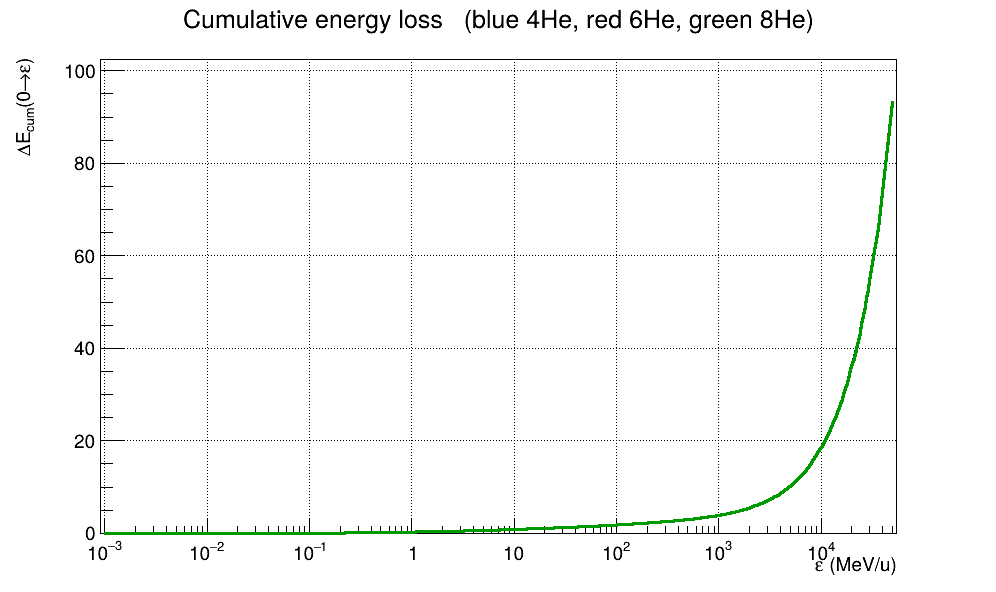

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_sn
Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig18_Fig1b_stopping_power.png has been created


[OK] Fig1a_cumulative -> /home/xugeng/experimental-methods/homework1.2/figs/fig17_Fig1a_cumulative.png


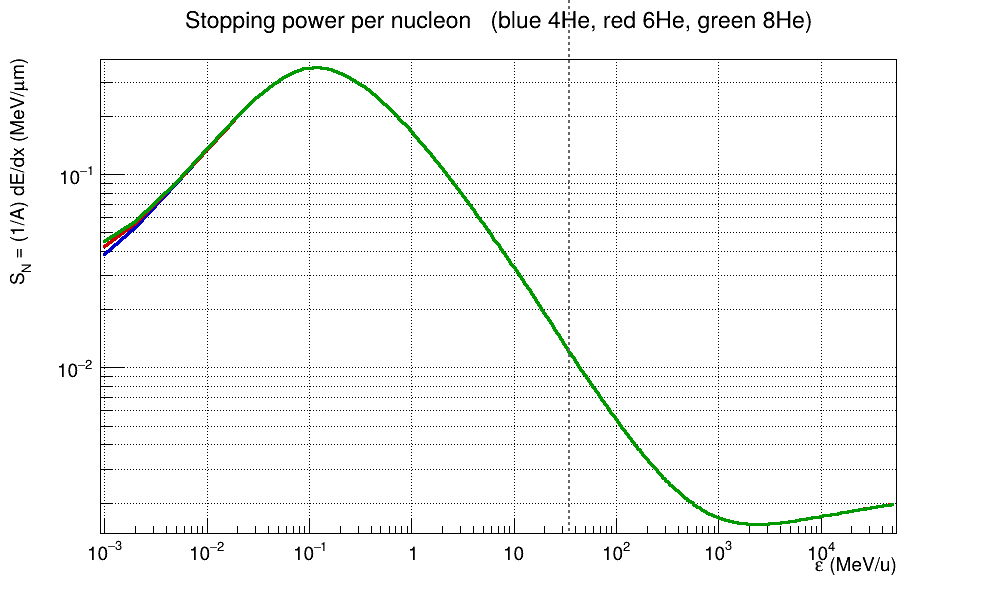

[OK] Fig1b_stopping_power -> /home/xugeng/experimental-methods/homework1.2/figs/fig18_Fig1b_stopping_power.png
[OK] Fig.1 已生成


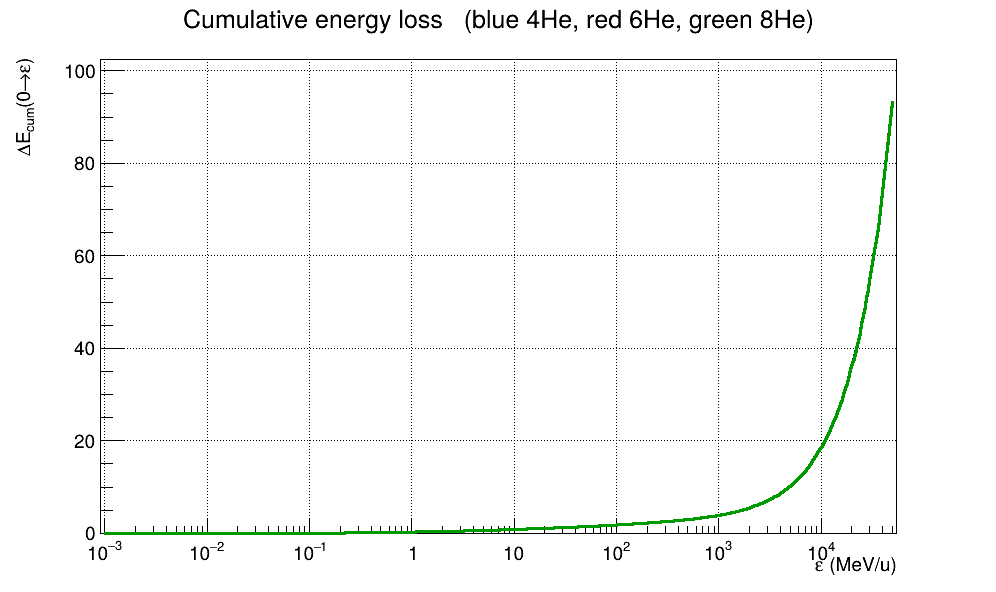

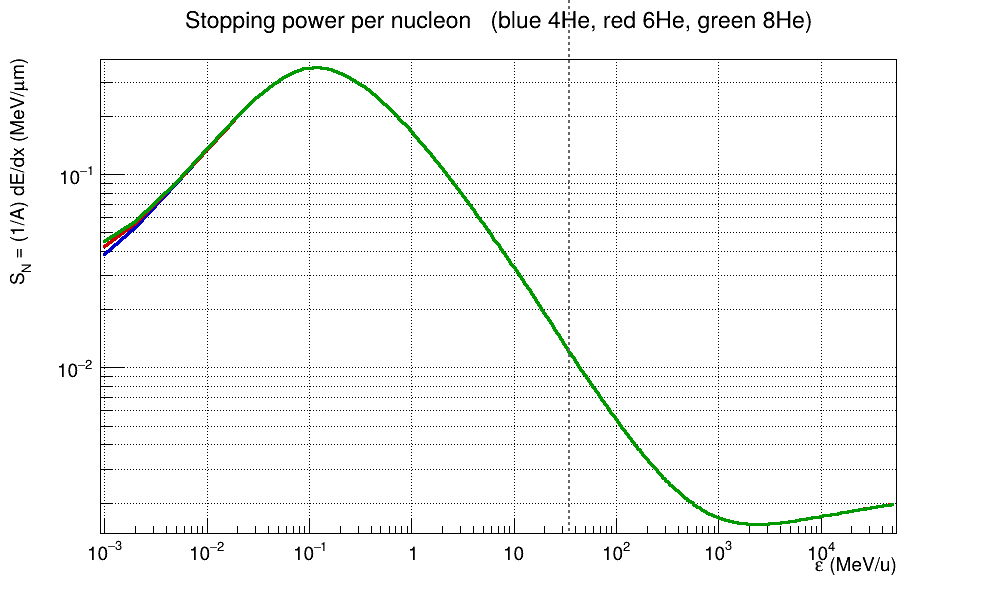

In [18]:
# ========== Cell 5：Fig.1a 累计能量损失 + Fig.1b 阻止本领 ==========
# 说明：本环境下 TCanvas::Divide() 的多子图渲染不可靠（部分子图会是空白），
# 因此每个面板单独画一张 canvas。下面所有图都遵循这一约定。
h1 = None
c = ROOT.TCanvas("c_cum", "Cumulative energy loss", 1000, 620)
c.SetLogx()
c.SetGrid()
for iso in HE_ISOTOPES:
    g = tgraph_xy(iso["cum_eps"], iso["cum_dE"])
    g.SetLineColor(iso["color"])
    g.SetLineWidth(3)
    if h1 is None:
        h1 = g
        g.SetTitle("Cumulative energy loss   (blue 4He, red 6He, green 8He);"
                   "#varepsilon (MeV/u);#DeltaE_{cum}(0#rightarrow#varepsilon)")
        g.GetYaxis().SetTitleOffset(1.35)
        g.GetYaxis().SetLimits(1e-3, 1e5)
    g.Draw("AL" if g is h1 else "L SAME")
show(c, "Fig1a_cumulative")

h2 = None
c = ROOT.TCanvas("c_sn", "Stopping power per nucleon", 1000, 620)
c.SetLogx()
c.SetLogy()
c.SetGrid()
for iso in HE_ISOTOPES:
    s = iso["dEdx"]
    g = tgraph_xy(s[:, 0], s[:, 1])
    g.SetLineColor(iso["color"])
    g.SetLineWidth(3)
    if h2 is None:
        h2 = g
        g.SetTitle("Stopping power per nucleon   (blue 4He, red 6He, green 8He);"
                   "#varepsilon (MeV/u);S_{N} = (1/A) dE/dx (MeV/#mum)")
        g.GetYaxis().SetTitleOffset(1.45)
        g.GetYaxis().SetLimits(1e-4, 1e1)
    g.Draw("AL" if g is h2 else "L SAME")
# 扫描窗口：用 frame 坐标画竖线（对数轴上用数据坐标会错位）
frame = c.GetFrame()
for e_win in (EPS_MIN, EPS_MAX):
    ln = ROOT.TLine(e_win, frame.GetY1(), e_win, frame.GetY2())
    ln.SetLineStyle(2)
    ln.SetLineColor(ROOT.kGray + 2)
    ln.SetLineWidth(2)
    ln.Draw()
show(c, "Fig1b_stopping_power")
print("[OK] Fig.1 已生成")

### 2.1 三种 He 同位素的同位素标度

用每核子能量 $\varepsilon=E/A$ 作横轴比较 4,6,8He：

- 相同 $\varepsilon$ 下阻止本领**接近**；
- 射程近似**与质量数成正比**：

$$R_{Z,A}(E)\approx\frac{A}{A_{\rm ref}}R_{Z,A_{\rm ref}}\left(E\frac{A_{\rm ref}}{A}\right)
\quad\Longleftrightarrow\quad
S_{Z,A}(E)\approx S_{Z,A_{\rm ref}}\left(E\frac{A_{\rm ref}}{A}\right)$$ 

下图左为 $S(\varepsilon)$，右为 $R(\varepsilon)$。右图同时画出
$R_{4\rm He}(\varepsilon)\times A/4$ 作为标度参考线（虚线）：若 ∝A 严格成立，
6He、8He 的实线应与对应虚线重合。

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_scale_s
Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig19_Fig2a_S_vs_eps.png has been created


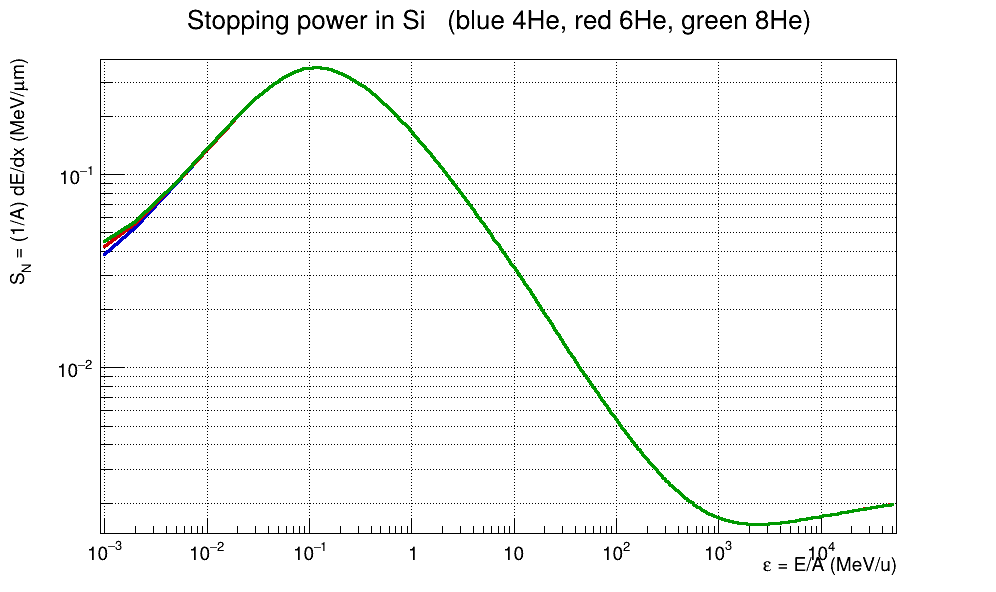

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_scale_r
Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig20_Fig2b_RN_vs_eps.png has been created


[OK] Fig2a_S_vs_eps -> /home/xugeng/experimental-methods/homework1.2/figs/fig19_Fig2a_S_vs_eps.png


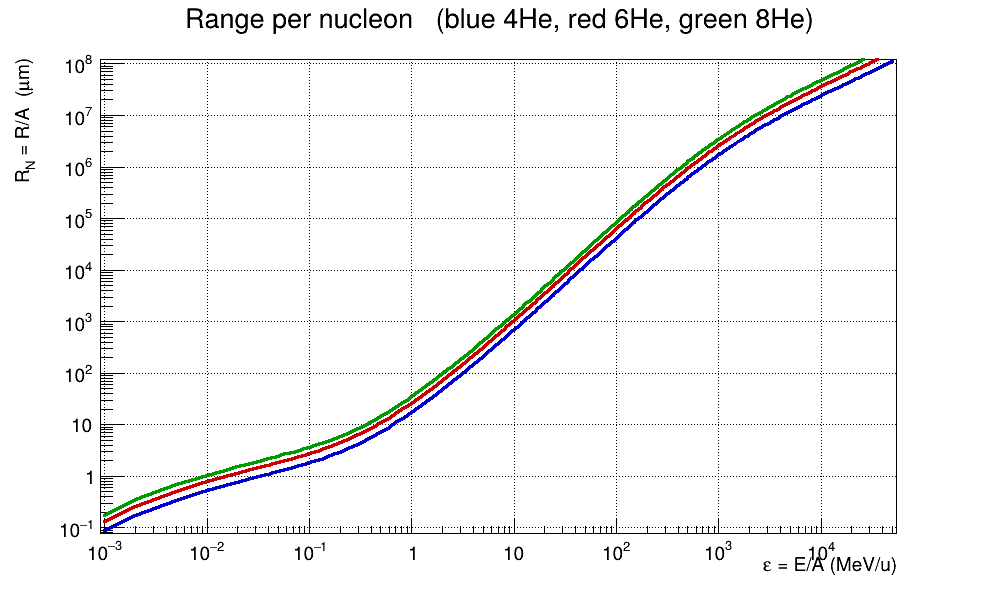

[OK] Fig2b_RN_vs_eps -> /home/xugeng/experimental-methods/homework1.2/figs/fig20_Fig2b_RN_vs_eps.png

========== 同位素标度检验（每核子射程） ==========
相同 eps 下，各同位素的 R_N = R/A 与 4He 的偏差：
   4He: min= +0.00%  max= +0.00%  mean= +0.00%
   6He: min=+50.39%  max=+50.39%  mean=+50.39%
   8He: min=+100.74%  max=+100.75%  mean=+100.75%
[OK] Fig.2 已生成


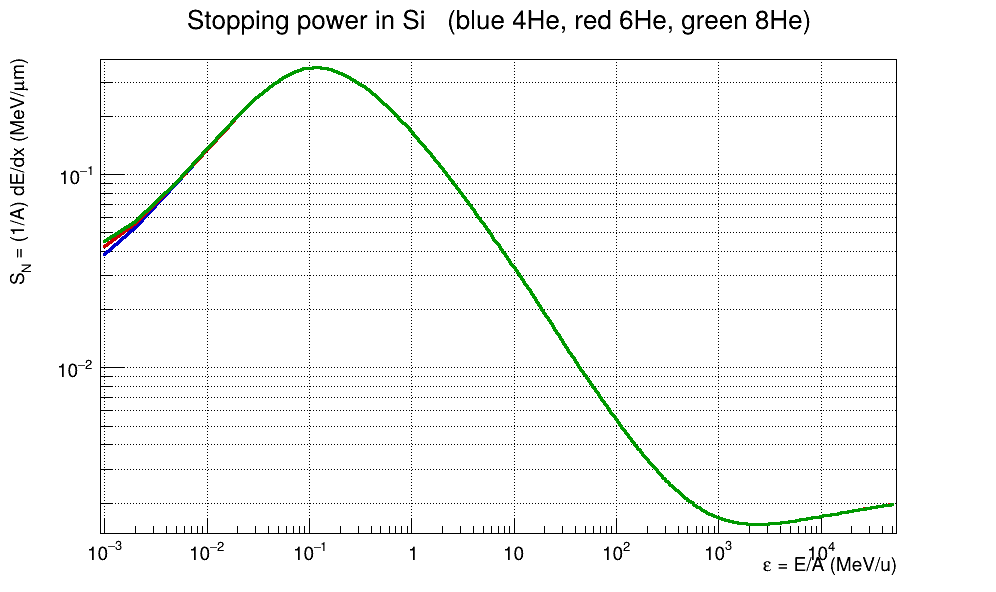

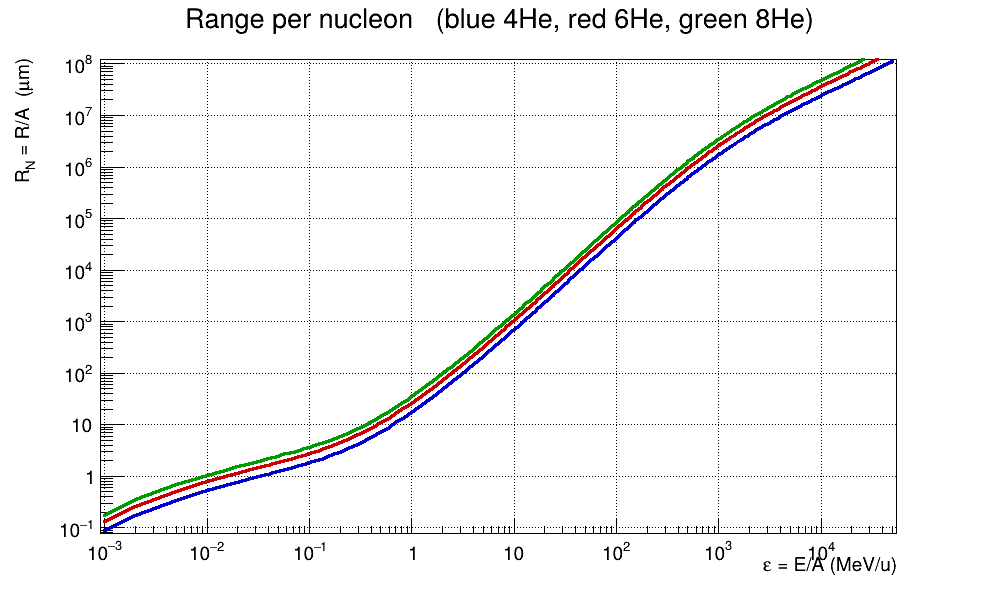

In [ ]:
# ========== Cell 6：Fig.2 同位素标度检验（两个面板各一张图）==========
hS = None
c = ROOT.TCanvas("c_scale_s", "Stopping power vs eps", 1000, 620)
c.SetLogx()
c.SetLogy()
c.SetGrid()
for iso in HE_ISOTOPES:
    s = iso["dEdx"]
    g = tgraph_xy(s[:, 0], s[:, 1])
    g.SetLineColor(iso["color"])
    g.SetLineWidth(3)
    if hS is None:
        hS = g
        g.SetTitle("Stopping power in Si   (blue 4He, red 6He, green 8He);"
                   "#varepsilon = E/A (MeV/u);S_{N} = (1/A) dE/dx (MeV/#mum)")
        g.GetYaxis().SetTitleOffset(1.45)
    g.Draw("AL" if g is hS else "L SAME")
show(c, "Fig2a_S_vs_eps")

# 判据：若 R ∝ A 严格成立，相同 eps 下 R_N = R/A 应与 A 无关，三条曲线应重合
hR = None
c = ROOT.TCanvas("c_scale_r", "Range per nucleon vs eps", 1000, 620)
c.SetLogx()
c.SetLogy()
c.SetGrid()
for iso in HE_ISOTOPES:
    r = iso["range"]
    g = tgraph_xy(r[:, 0], r[:, 1])
    g.SetLineColor(iso["color"])
    g.SetLineWidth(3)
    if hR is None:
        hR = g
        g.SetTitle("Range per nucleon   (blue 4He, red 6He, green 8He);"
                   "#varepsilon = E/A (MeV/u);R_{N} = R/A  (#mum)")
        g.GetYaxis().SetTitleOffset(1.35)
        g.GetYaxis().SetLimits(0.5, 2.0e5)
    g.Draw("AL" if g is hR else "L SAME")
show(c, "Fig2b_RN_vs_eps")

print()
print("========== 同位素标度检验（每核子射程） ==========")
ref4 = HE_ISOTOPES[0]["range"]
mask = (ref4[:, 0] >= EPS_MIN) & (ref4[:, 0] <= EPS_MAX)
eps_cmp = ref4[mask, 0]
R4 = ref4[mask, 1]
print("相同 eps 下，各同位素的 R_N = R/A 与 4He 的偏差：")
for iso in HE_ISOTOPES:
    r = iso["range"]
    R_iso_N = np.interp(eps_cmp, r[:, 0], r[:, 1])
    dev = 100.0 * (R_iso_N - R4) / R4
    print("  %4s: min=%+6.2f%%  max=%+6.2f%%  mean=%+6.2f%%" % (iso["name"], dev.min(), dev.max(), dev.mean()))
print("[OK] Fig.2 已生成")

## 3. 建立射程-能量关系 R(E) 与反函数 E(R)

射程数据是离散的，在数据覆盖的能区内做合理插值：

- $R(E)$：对射程表直接线性插值（射程随能量单调上升）；
- $E(R)$：交换自变量后插值，即反函数；$R=0$ 对应 $E=0$；
- 其他同位素按 $R_{Z,A}(E)\approx\dfrac{A}{A_{\rm ref}}R_{Z,A_{\rm ref}}\left(E\dfrac{A_{\rm ref}}{A}\right)$
  换算。本部分 4,6,8He 都有各自的射程表，取 $A_{\rm ref}=A$ 即可，不依赖该近似；
  该近似在 Z=1...8 扩展时用于生成缺少数据的同位素。

单层能量沉积公式：

$$R_{\rm out}=\max\left[R(E_{\rm in})-t,\,0\right],\qquad E_{\rm out}=E(R_{\rm out}),\qquad
\Delta E=E_{\rm in}-E_{\rm out}$$ 

当 $R_{\rm out}=0$ 时粒子已在层内停止，直接令 $E_{\rm out}=0$、$\Delta E=E_{\rm in}$。

In [8]:
# ========== Cell 7：RangeEnergy 类与单层能损 ==========
class RangeEnergy(object):
    # 封装一个 (Z, A) 的 R(E) 与 E(R)，支持同位素换算与逐层能损。
    #
    # 【单位与约定】
    # LISE++ 的射程列是【每核子】射程 R_N (μm)，阻止本领列也是【每核子】值。
    # 完整离子的量需乘质量数 A：R(μm) = A * R_N，-dE/dx(MeV/μm) = A * S_N。
    # 该换算由 Cell 4 的闭环检验确定：∫ dε/S_N 恰好等于射程列，两者只差因子 A。
    # 本类对外一律使用完整离子的量：E 为 MeV，R 为 μm，厚度 t 为 μm。

    def __init__(self, Z, A, range_data, A_ref=None):
        self.Z = Z
        self.A = A
        self.A_ref = A if A_ref is None else A_ref

        eps = range_data[:, 0]
        R = range_data[:, 1]
        # R_N 必须严格单调上升才能求反函数：网格上出现相等值时去掉重复点
        keep = np.concatenate(([True], np.diff(R) > 0))
        self.eps_tab = eps[keep]
        self.R_tab_N = R[keep]                      # 每核子射程 (μm)

        # 参考同位素 -> 目标同位素的换算系数：eps_ref = eps / k, R_N,ref = R_N / k
        self.k = float(self.A) / float(self.A_ref)

    # ---- 每核子能量 -> 完整离子射程 (μm) ----
    def R_of_eps(self, eps):
        eps = np.asarray(eps, dtype=float)
        eps_ref = eps / self.k                      # 换回参考同位素的横轴
        R_N_ref = np.interp(eps_ref, self.eps_tab, self.R_tab_N, left=0.0, right=np.nan)
        return R_N_ref * self.k * self.A

    # ---- 完整离子射程 (μm) -> 每核子能量 (MeV/u) ----
    def eps_of_R(self, R):
        R = np.asarray(R, dtype=float)
        R_N_ref = np.clip(R / (self.k * self.A), 0.0, self.R_tab_N[-1])
        eps_ref = np.interp(R_N_ref, self.R_tab_N, self.eps_tab)
        return eps_ref * self.k

    # ---- 原始每核子射程表（仅用于与数据文件直接对照）----
    def R_N_of_eps(self, eps):
        return np.interp(np.asarray(eps, dtype=float), self.eps_tab, self.R_tab_N)

    # ---- 总能量接口 ----
    def R_of_E(self, E):
        return self.R_of_eps(np.asarray(E, dtype=float) / self.A)

    def E_of_R(self, R):
        return self.eps_of_R(R) * self.A

    # ---- 单层能量沉积 ----
    def deposit(self, E_in, t):
        # 返回 (ΔE, E_out)。R_out = max(R(E_in) - t, 0)，R_out = 0 表示停在层内。
        E_in = np.asarray(E_in, dtype=float)
        R_in = self.R_of_E(E_in)                     # μm
        R_out = np.maximum(R_in - t, 0.0)            # μm
        stopped = R_out <= 0.0
        E_out = np.where(stopped, 0.0, np.nan_to_num(self.E_of_R(R_out), nan=0.0))
        return E_in - E_out, E_out

    # ---- 剩余射程（用于解释分支走向）----
    def range_after(self, E_in, t):
        return np.maximum(self.R_of_E(E_in) - t, 0.0)


# 4,6,8He 各自都有射程表，因此取 A_ref = A 建立对象，不引入同位素近似
RE = {}
for iso in HE_ISOTOPES:
    RE[iso["name"]] = RangeEnergy(Z=2, A=iso["A"], range_data=iso["range"], A_ref=iso["A"])
print("[OK] RangeEnergy 对象建立:", ", ".join(sorted(RE.keys())))

# ---- 每核子射程一致性抽查：R(E)/A 应与射程列的原始数值一致 ----
print()
print("========== 每核子射程一致性抽查 ==========")
for iso in HE_ISOTOPES:
    obj = RE[iso["name"]]
    for eps in (5.0, 10.0, 25.0):
        R_N_calc = float(obj.R_of_E(iso["A"] * eps)) / iso["A"]
        R_N_tab = float(obj.R_N_of_eps(eps))
        print("  %4s eps=%5.1f MeV/u : R(μm)/A=%9.3f vs 射程列=%9.3f (偏差=%+.4f%%)"
              % (iso["name"], eps, R_N_calc, R_N_tab,
                 100.0 * (R_N_calc - R_N_tab) / R_N_tab))

# ---- 边界与自洽性检查 ----
print()
print("========== 单层能损边界检查 ==========")
for name in ("4He", "6He", "8He"):
    obj = RE[name]
    E = 100.0
    R_E = float(obj.R_of_E(E))
    dE0, Eout0 = obj.deposit(E, 0.0)                 # t = 0
    dE1u, Eout1u = obj.deposit(E, 1.0)               # 1 μm 薄层
    dE2u, _ = obj.deposit(E, 2.0)                    # 2 μm，检验薄层线性
    dEall, Eoutall = obj.deposit(E, R_E * 1.5)       # 厚度超过射程
    print("%s E=%6.1f MeV (R=%9.1f μm):" % (name, E, R_E))
    print("    t = 0     -> ΔE = %9.4f MeV, E_out = %9.4f MeV" % (float(dE0), float(Eout0)))
    print("    t = 1 μm  -> ΔE = %9.4f MeV, E_out = %9.4f MeV" % (float(dE1u), float(Eout1u)))
    print("    t = 1.5R  -> ΔE = %9.4f MeV, E_out = %9.4f MeV (应等于 E_in = %g)"
          % (float(dEall), float(Eoutall), E))
    print("    ΔE(2μm)/ΔE(1μm) = %8.4f (薄层极限应接近 2)" % (float(dE2u) / float(dE1u)))

[OK] RangeEnergy 对象建立: 4He, 6He, 8He

========== 每核子射程一致性抽查 ==========
   4He eps=  5.0 MeV/u : R(μm)/A=  213.088 vs 射程列=  213.088 (偏差=+0.0000%)
   4He eps= 10.0 MeV/u : R(μm)/A=  696.917 vs 射程列=  696.917 (偏差=+0.0000%)
   4He eps= 25.0 MeV/u : R(μm)/A= 3511.830 vs 射程列= 3511.830 (偏差=+0.0000%)
   6He eps=  5.0 MeV/u : R(μm)/A=  320.459 vs 射程列=  320.459 (偏差=+0.0000%)
   6He eps= 10.0 MeV/u : R(μm)/A= 1048.080 vs 射程列= 1048.080 (偏差=+0.0000%)
   6He eps= 25.0 MeV/u : R(μm)/A= 5281.380 vs 射程列= 5281.380 (偏差=+0.0000%)
   8He eps=  5.0 MeV/u : R(μm)/A=  427.764 vs 射程列=  427.764 (偏差=+0.0000%)
   8He eps= 10.0 MeV/u : R(μm)/A= 1399.030 vs 射程列= 1399.030 (偏差=+0.0000%)
   8He eps= 25.0 MeV/u : R(μm)/A= 7049.840 vs 射程列= 7049.840 (偏差=+0.0000%)

========== 单层能损边界检查 ==========
4He E= 100.0 MeV (R=  14047.3 μm):
    t = 0     -> ΔE =    0.0000 MeV, E_out =  100.0000 MeV
    t = 1 μm  -> ΔE =    0.0040 MeV, E_out =   99.9960 MeV
    t = 1.5R  -> ΔE =  100.0000 MeV, E_out =    0.0000 MeV (应等于 E_in = 100)
  

### 3.1 射程清单

列出 10、100、200 MeV 的 4He、12C、16O 在 Si 中的射程。
4He 用本目录的射程表；12C、16O 的射程表位于 `data/element1-8/`，本部分尚未接入，
因此这里先完整给出 4He，12C/16O 待 element1-8 部分补全。

In [9]:
# ========== Cell 8：10/100/200 MeV 的射程清单 ==========
print("========== 射程清单（Si） ==========")
print("%6s %10s %13s %14s" % ("核素", "E (MeV)", "E/A (MeV/u)", "R (μm)"))
for name in ("4He", "6He", "8He"):
    obj = RE[name]
    for E in (10.0, 100.0, 200.0):
        print("%6s %10.1f %13.3f %14.2f" % (name, E, E / obj.A, float(obj.R_of_E(E))))

print()
print("========== 反函数闭环检查 R -> E -> R ==========")
for name in ("4He", "6He", "8He"):
    obj = RE[name]
    for eps in (5.0, 15.0, 30.0):
        E = obj.A * eps
        R = float(obj.R_of_E(E))
        E_back = float(obj.E_of_R(R))
        print("%4s: eps=%5.1f -> R=%10.2f μm -> eps_back=%7.4f MeV/u (相对偏差 %+.2e %%)"
              % (name, eps, R, E_back / obj.A, 100.0 * (E_back - E) / E))

========== 射程清单（Si） ==========
    核素    E (MeV)   E/A (MeV/u)         R (μm)
   4He       10.0         2.500         273.72
   4He      100.0        25.000       14047.32
   4He      200.0        50.000       48973.20
   6He       10.0         1.667         330.18
   6He      100.0        16.667       15387.56
   6He      200.0        33.333       53286.58
   8He       10.0         1.250         383.37
   8He      100.0        12.500       16521.24
   8He      200.0        25.000       56398.72

========== 反函数闭环检查 R -> E -> R ==========
 4He: eps=  5.0 -> R=    852.35 μm -> eps_back= 5.0000 MeV/u (相对偏差 +0.00e+00 %)
 4He: eps= 15.0 -> R=   5660.44 μm -> eps_back=15.0000 MeV/u (相对偏差 +0.00e+00 %)
 4He: eps= 30.0 -> R=  19533.58 μm -> eps_back=30.0000 MeV/u (相对偏差 +0.00e+00 %)
 6He: eps=  5.0 -> R=   1922.75 μm -> eps_back= 5.0000 MeV/u (相对偏差 +0.00e+00 %)
 6He: eps= 15.0 -> R=  12768.96 μm -> eps_back=15.0000 MeV/u (相对偏差 +0.00e+00 %)
 6He: eps= 30.0 -> R=  44064.27 μm -> eps_back=30.0000 M

## 4. 三层 Si 望远镜仿真（实验设置 1000 / 500 / 1000 μm）

逐层递推：

$$\Delta E_1=\mathrm{deposit}(E,\,1000),\quad E_1=\mathrm{out}(E,\,1000),\quad
\Delta E_2=\mathrm{deposit}(E_1,\,500),\quad \Delta E_3=\mathrm{deposit}(E_2,\,1000)$$ 

停止层标记（与实验数据处理页的操作性判据对应）：

| 标记 | 含义 | 实验判据 |
|---|---|---|
| `stop = 1` | 停在 D1 | D2、D3 无信号 |
| `stop = 2` | 停在 D2 | $\Delta E_3<1$ MeV |
| `stop = 3` | 停在 D3 | $\Delta E_3>2$ MeV |
| `stop = 0` | 穿出 D3 | 按实验设置应极少出现 |

这里先做**理想能量沉积**（不加探测器分辨），分辨率模型在下一部分处理。

In [10]:
# ========== Cell 9：三层望远镜逐层递推 ==========
def simulate_telescope(E_in, obj, layers=(T1, T2, T3)):
    # 逐层计算能量沉积，返回各层读出与剩余量的字典（数组长度同 E_in）。
    #
    # dE1/dE2/dE3 : 三层沉积能量 (MeV)
    # E1/E2/E3    : 各层出射剩余能量 (MeV)，E3 为 D3 出射能量
    # R1/R2/R3    : 各层入射时的射程 (μm)，即该层入口处的剩余射程
    # stop        : 停止层 1/2/3，0 表示穿出 D3
    E_in = np.asarray(E_in, dtype=float)
    t1, t2, t3 = layers

    R0 = obj.R_of_E(E_in)
    dE1, E1 = obj.deposit(E_in, t1)
    R1 = np.maximum(R0 - t1, 0.0)
    dE2, E2 = obj.deposit(E1, t2)
    R2 = np.maximum(R1 - t2, 0.0)
    dE3, E3 = obj.deposit(E2, t3)
    R3 = np.maximum(R2 - t3, 0.0)

    stop = np.where(E1 <= 0.0, 1, np.where(E2 <= 0.0, 2, np.where(E3 <= 0.0, 3, 0)))

    return {"dE1": dE1, "dE2": dE2, "dE3": dE3,
            "E1": E1, "E2": E2, "E3": E3,
            "R1": R1, "R2": R2, "R3": R3, "stop": stop}


def make_eps_grid(eps_min=EPS_MIN, eps_max=EPS_MAX, n=N_EPS):
    # 线性 + 对数混合网格。能损对能量高度非线性：纯线性网格在低能端太稀，
    # 纯对数网格在高能端太密，混合网格兼顾两端。
    eps_lin = np.linspace(eps_min, eps_max, n)
    eps_log = np.geomspace(eps_min, eps_max, n)
    return np.unique(np.concatenate([eps_lin, eps_log]))


EPS_GRID = make_eps_grid()
print("[OK] eps 网格: %d 点, %g ... %g MeV/u" % (len(EPS_GRID), EPS_GRID[0], EPS_GRID[-1]))

[OK] eps 网格: 1198 点, 1 ... 35 MeV/u


In [11]:
# ========== Cell 10：对 4,6,8He 运行仿真 ==========
print("========== 三层望远镜仿真（理想能量沉积） ==========")
for iso in HE_ISOTOPES:
    obj = RE[iso["name"]]
    E_in = obj.A * EPS_GRID
    iso["eps"] = EPS_GRID
    iso["E_in"] = E_in
    iso["sim"] = simulate_telescope(E_in, obj)

    stop = iso["sim"]["stop"]
    print()
    print("--- %s (A=%d) ---" % (iso["name"], iso["A"]))
    for layer in (1, 2, 3, 0):
        m = stop == layer
        tag = "穿出 D3" if layer == 0 else "停在 D%d" % layer
        if not m.any():
            print("  %8s: 无事件" % tag)
            continue
        e_lo, e_hi = EPS_GRID[m].min(), EPS_GRID[m].max()
        print("  %8s: %4d 点, eps = %6.3f ... %6.3f MeV/u (E = %7.2f ... %7.2f MeV)"
              % (tag, m.sum(), e_lo, e_hi, e_lo * iso["A"], e_hi * iso["A"]))

    m2, m3 = stop == 2, stop == 3
    if m2.any() and m3.any():
        eps_pt = EPS_GRID[m3].min()
        print("  -> 网格上首次进入 D3 的 eps = %.4f MeV/u (E = %.3f MeV)"
              % (eps_pt, eps_pt * iso["A"]))

========== 三层望远镜仿真（理想能量沉积） ==========

--- 4He (A=4) ---
     停在 D1:  367 点, eps =  1.000 ...  5.493 MeV/u (E =    4.00 ...   21.97 MeV)
     停在 D2:   66 点, eps =  5.526 ...  6.965 MeV/u (E =   22.10 ...   27.86 MeV)
     停在 D3:   92 点, eps =  7.006 ...  9.371 MeV/u (E =   28.03 ...   37.49 MeV)
     穿出 D3:  673 点, eps =  9.401 ... 35.000 MeV/u (E =   37.60 ...  140.00 MeV)
  -> 网格上首次进入 D3 的 eps = 7.0065 MeV/u (E = 28.026 MeV)

--- 6He (A=6) ---
     停在 D1:  246 点, eps =  1.000 ...  3.356 MeV/u (E =    6.00 ...   20.14 MeV)
     停在 D2:   58 点, eps =  3.376 ...  4.292 MeV/u (E =   20.26 ...   25.75 MeV)
     停在 D3:   79 点, eps =  4.307 ...  5.829 MeV/u (E =   25.84 ...   34.97 MeV)
     穿出 D3:  815 点, eps =  5.864 ... 35.000 MeV/u (E =   35.18 ...  210.00 MeV)
  -> 网格上首次进入 D3 的 eps = 4.3065 MeV/u (E = 25.839 MeV)

--- 8He (A=8) ---
     停在 D1:  168 点, eps =  1.000 ...  2.351 MeV/u (E =    8.00 ...   18.81 MeV)
     停在 D2:   54 点, eps =  2.362 ...  3.016 MeV/u (E =   18.90 ...   24.13 Me

## 5. ΔE1-ΔE2 与 ΔE2-ΔE3 关联图

坐标轴与实验数据处理页保持一致：

- ΔE1-ΔE2：横轴 $\Delta E_2$、纵轴 $\Delta E_1$；
- ΔE2-ΔE3：横轴 $\Delta E_3$、纵轴 $\Delta E_2$。

颜色按实验页的操作性判据划分：

- **蓝**：$\Delta E_3<1$ MeV —— 与「停止在 D2」相符（`stop == 2`）；
- **红**：$\Delta E_3>2$ MeV —— 与「到达 D3」相符（`stop == 3`）。

理想计算的条带非常锐利，用 TH2 分箱会把它抹成离散点阵，因此这里用**细点标记的 TGraph**
逐点画出仿真条带；右下把三个同位素叠加，便于比较条带位置与形状。

  3_dE1dE2 4He: canvas primitives = 3


Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig05_Fig3_dE1dE2_4He.png has been created


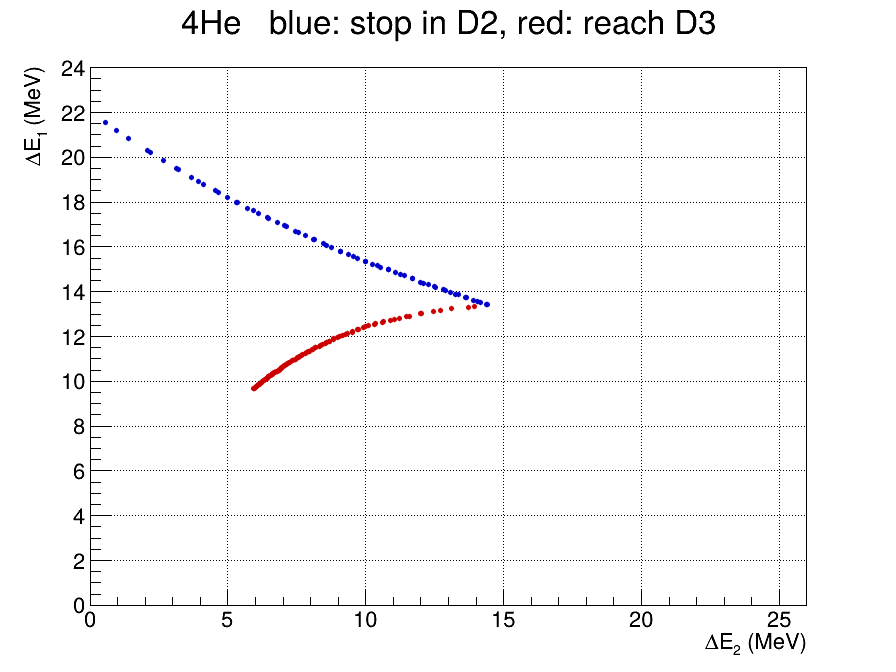

Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig06_Fig3_dE1dE2_6He.png has been created


[OK] Fig3_dE1dE2_4He -> /home/xugeng/experimental-methods/homework1.2/figs/fig05_Fig3_dE1dE2_4He.png
  3_dE1dE2 6He: canvas primitives = 3


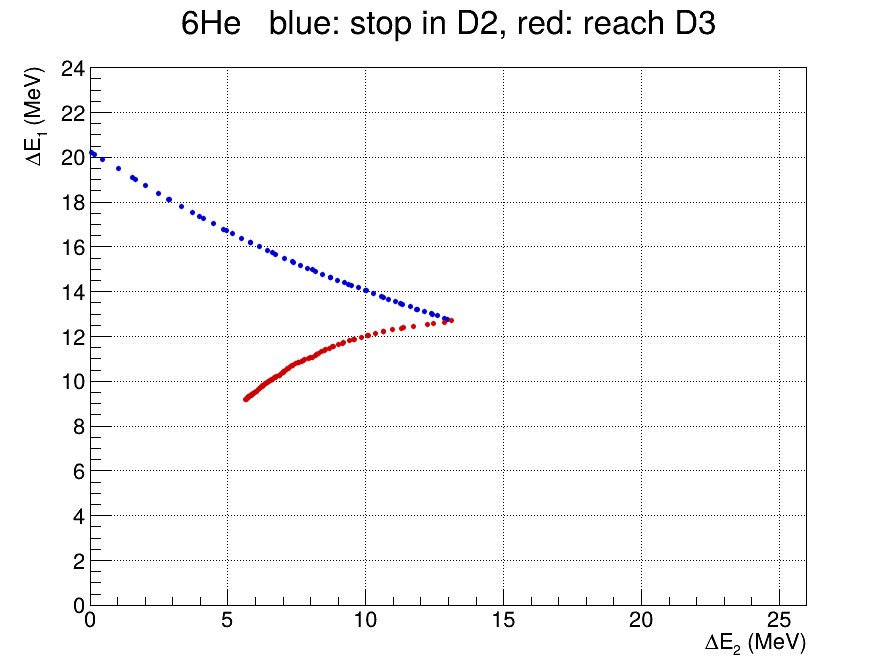

Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig07_Fig3_dE1dE2_8He.png has been created


[OK] Fig3_dE1dE2_6He -> /home/xugeng/experimental-methods/homework1.2/figs/fig06_Fig3_dE1dE2_6He.png
  3_dE1dE2 8He: canvas primitives = 3


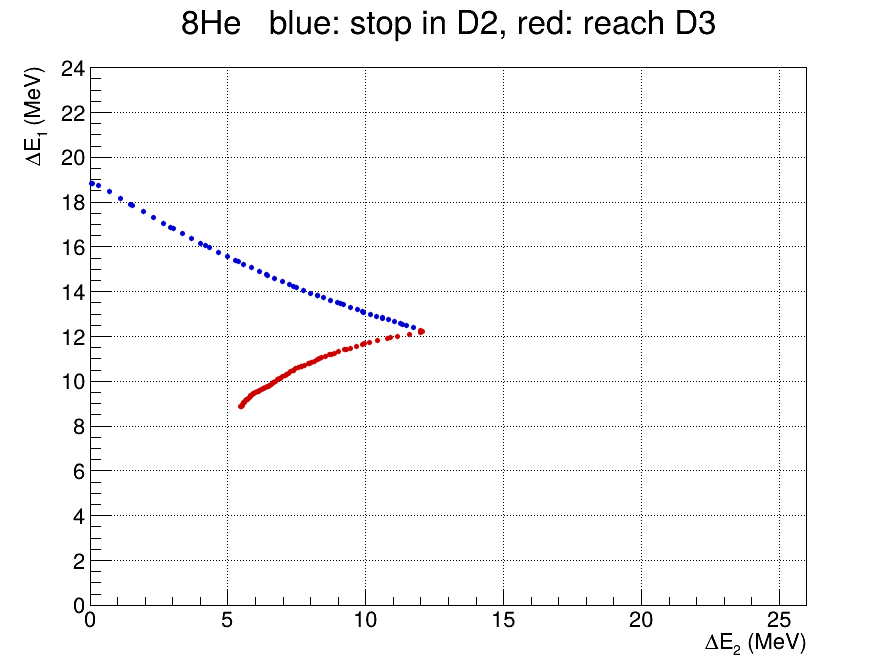

[OK] Fig3_dE1dE2_8He -> /home/xugeng/experimental-methods/homework1.2/figs/fig07_Fig3_dE1dE2_8He.png
  3_dE1dE2 overlaid: canvas primitives = 7


Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig08_Fig3_dE1dE2_overlaid.png has been created


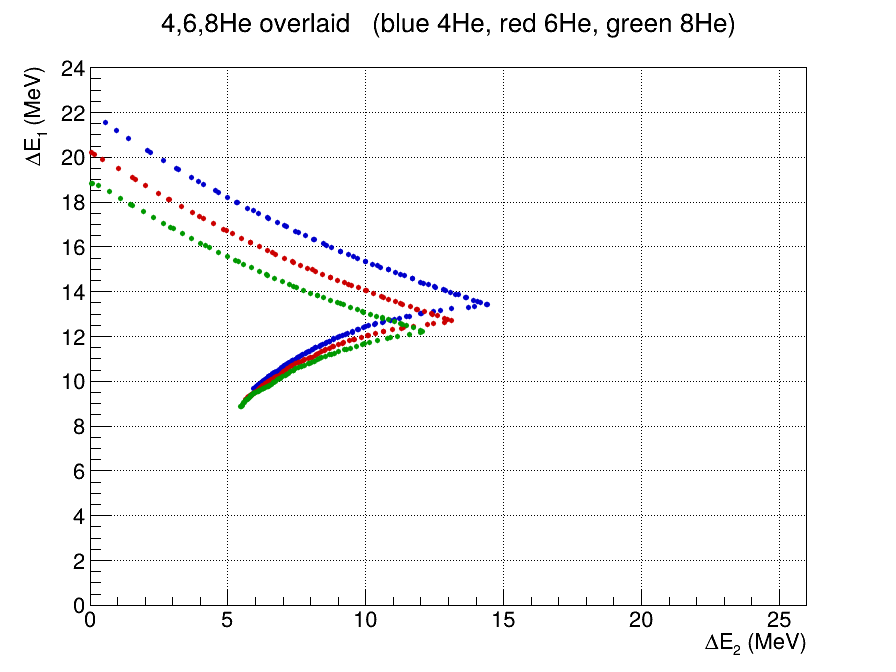

[OK] Fig3_dE1dE2_overlaid -> /home/xugeng/experimental-methods/homework1.2/figs/fig08_Fig3_dE1dE2_overlaid.png
[OK] Fig.3 ΔE1-ΔE2 关联图（4,6,8He）已生成


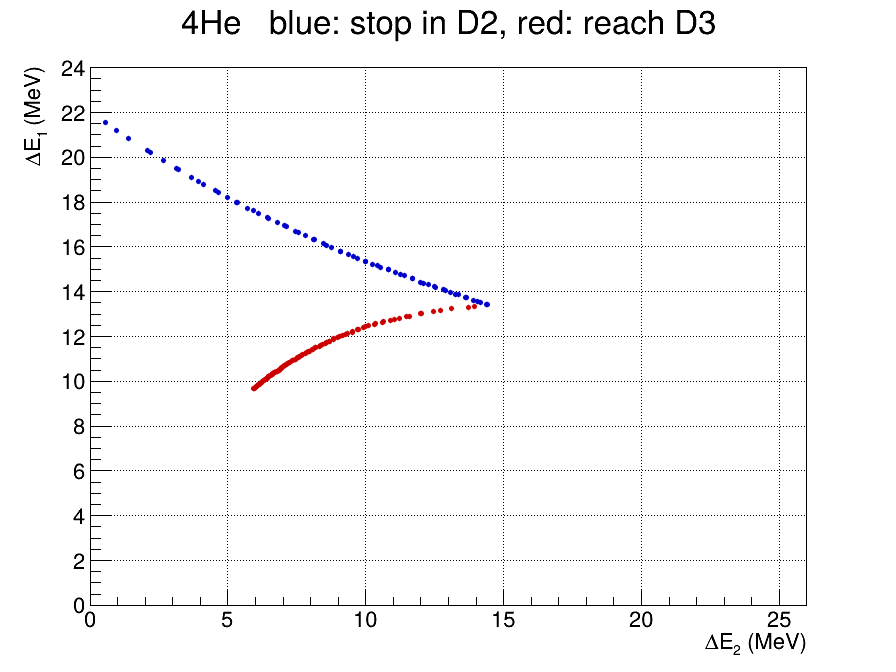

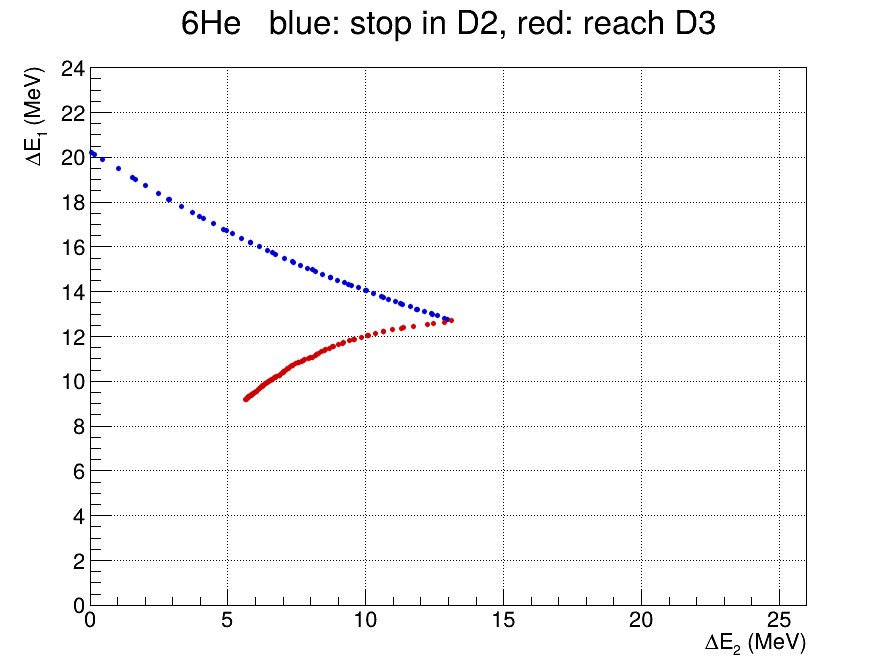

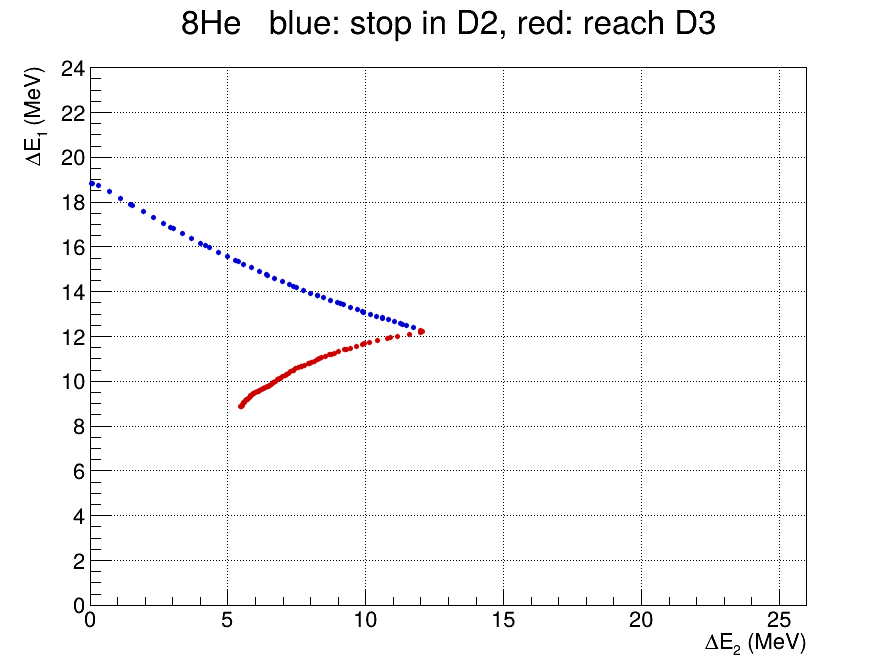

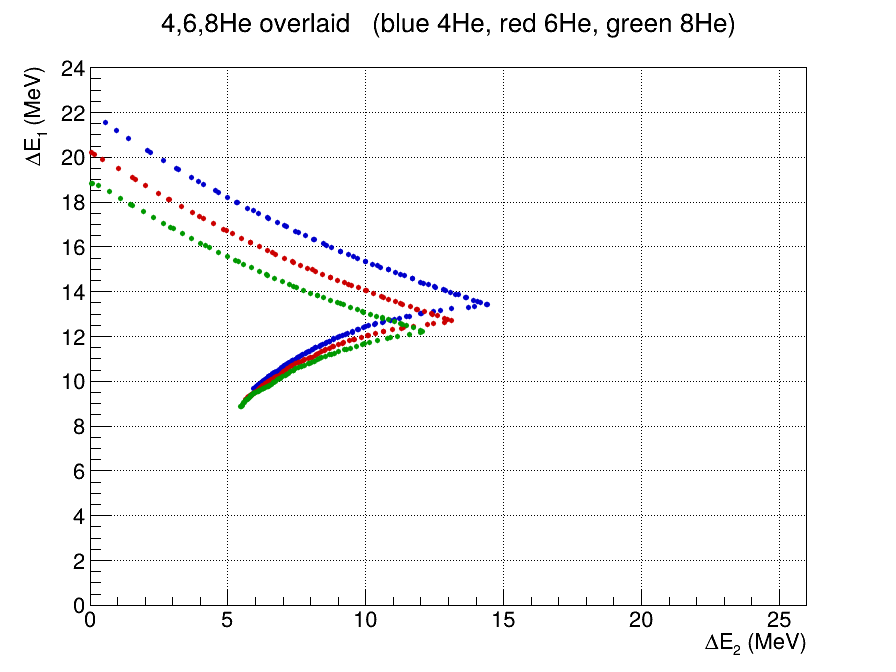

In [12]:
# ========== Cell 11：Fig.3 ΔE1-ΔE2 关联图（4,6,8He 各一张 + 叠加一张）==========
C_STOP = ROOT.kBlue + 1     # dE3 < 1 MeV  -> 停止在 D2
C_PUNCH = ROOT.kRed + 1     # dE3 > 2 MeV  -> 到达 D3

# 【重要】ROOT 对象（TH2D / TGraph）必须由 Python 端持有引用：
# 如果只写 make_frame(...).Draw() 而丢掉返回值，Python 会立刻回收这个对象，
# TCanvas 上只剩 0 个 primitive，导出的 PNG 就是空白。
# 因此下面统一把 TH2D 和 TGraph 存进 _keep 列表，canvas 存进 _canvases。
_keep = []
_canvases = []


def tgraph_xy(x, y):
    """由两个一维数组构造 TGraph，并保持 numpy 缓冲存活。"""
    x = np.ascontiguousarray(np.asarray(x, dtype=np.float64).ravel())
    y = np.ascontiguousarray(np.asarray(y, dtype=np.float64).ravel())
    g = ROOT.TGraph(len(x), x, y)
    g.__dict__["_keep_str"] = (x, y)
    _keep.append(g)
    return g


def make_pid_graph(x, y, color, marker=20, msize=0.5):
    # 仿真条带用细点 TGraph：理想计算的条带非常锐利，TH2 分箱会把它打散
    g = tgraph_xy(x, y)
    g.SetMarkerStyle(marker)
    g.SetMarkerSize(msize)
    g.SetMarkerColor(color)
    return g


def make_pid_frame(name, title, xtitle, ytitle, xmax=26.0, ymax=24.0):
    # 白色空 TH2D 作坐标框架（TGraph 单独画时不好控制轴范围）
    h = ROOT.TH2D(name, "%s;%s;%s" % (title, xtitle, ytitle),
                  520, 0.0, xmax, 520, 0.0, ymax)
    h.SetFillColor(ROOT.kWhite)
    h.Draw()
    _keep.append(h)      # 关键：保住引用
    return h


def draw_pid_panels(tag, xtitle, ytitle, x_key, y_key, xmax=26.0, ymax=24.0):
    """每个同位素一张图，另加一张三者叠加图。"""
    for iso in HE_ISOTOPES:
        c = ROOT.TCanvas("c_%s_%s" % (tag, iso["name"]), tag, 900, 700)
        _canvases.append(c)
        c.SetGrid()
        make_pid_frame("h_%s_%s" % (tag, iso["name"]),
                       "%s   blue: stop in D2, red: reach D3" % iso["name"],
                       xtitle, ytitle, xmax, ymax)
        sim = iso["sim"]
        m_stop = sim["stop"] == 2
        m_punch = sim["stop"] == 3
        make_pid_graph(sim[x_key][m_stop], sim[y_key][m_stop], C_STOP).Draw("P SAME")
        make_pid_graph(sim[x_key][m_punch], sim[y_key][m_punch], C_PUNCH).Draw("P SAME")
        print("  %s %s: canvas primitives = %d"
              % (tag, iso["name"], c.GetListOfPrimitives().GetEntries()))
        show(c, "Fig%s_%s" % (tag, iso["name"]))

    c = ROOT.TCanvas("c_%s_all" % tag, tag, 900, 700)
    _canvases.append(c)
    c.SetGrid()
    make_pid_frame("h_%s_all" % tag,
                   "4,6,8He overlaid   (blue 4He, red 6He, green 8He)",
                   xtitle, ytitle, xmax, ymax)
    for iso in HE_ISOTOPES:
        sim = iso["sim"]
        for m in (sim["stop"] == 2, sim["stop"] == 3):
            make_pid_graph(sim[x_key][m], sim[y_key][m], iso["color"]).Draw("P SAME")
    print("  %s overlaid: canvas primitives = %d" % (tag, c.GetListOfPrimitives().GetEntries()))
    show(c, "Fig%s_overlaid" % tag)


# Fig.3：ΔE1-ΔE2（横轴 ΔE2、纵轴 ΔE1，与实验数据处理页一致）
draw_pid_panels("3_dE1dE2", "#DeltaE_{2} (MeV)", "#DeltaE_{1} (MeV)", "dE2", "dE1")
print("[OK] Fig.3 ΔE1-ΔE2 关联图（4,6,8He）已生成")

Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig09_Fig4_dE2dE3_4He.png has been created


  4_dE2dE3 4He: canvas primitives = 3


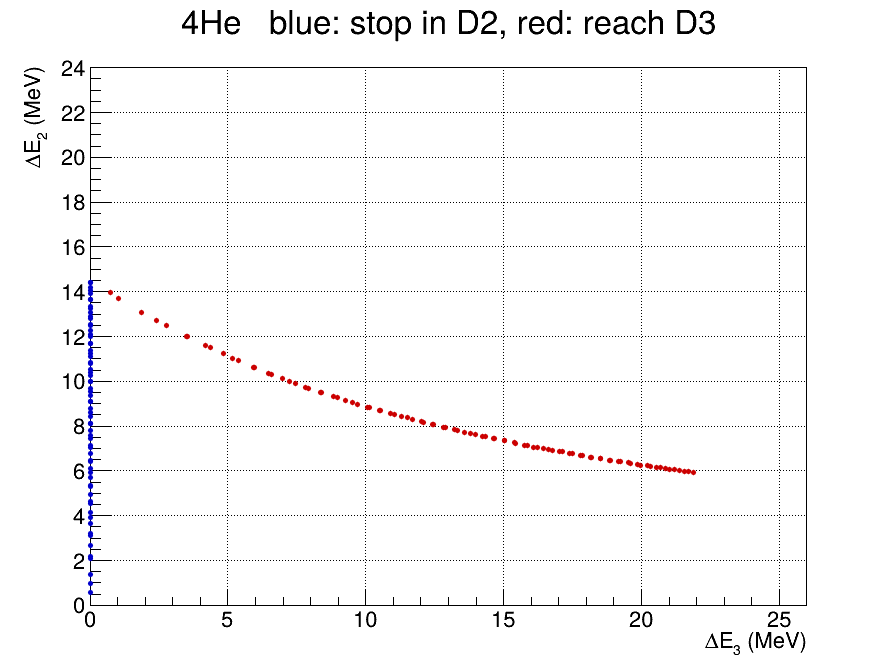

Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig10_Fig4_dE2dE3_6He.png has been created


[OK] Fig4_dE2dE3_4He -> /home/xugeng/experimental-methods/homework1.2/figs/fig09_Fig4_dE2dE3_4He.png
  4_dE2dE3 6He: canvas primitives = 3


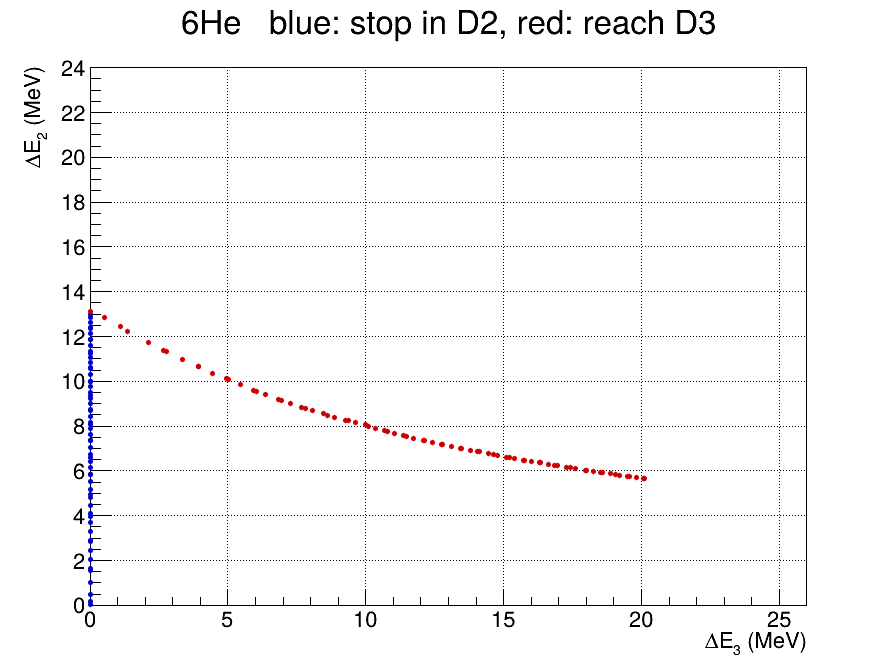

Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig11_Fig4_dE2dE3_8He.png has been created


[OK] Fig4_dE2dE3_6He -> /home/xugeng/experimental-methods/homework1.2/figs/fig10_Fig4_dE2dE3_6He.png
  4_dE2dE3 8He: canvas primitives = 3


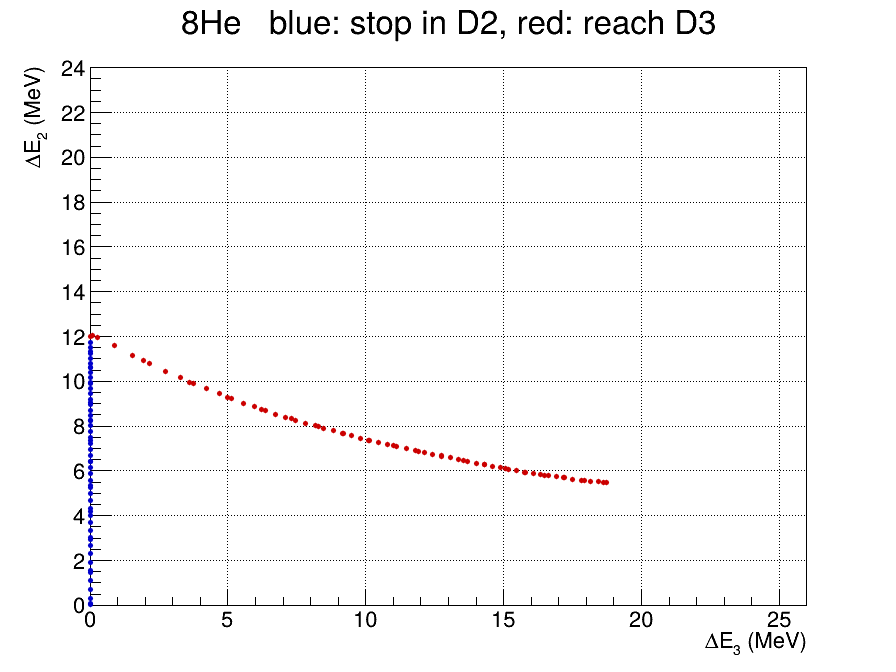

[OK] Fig4_dE2dE3_8He -> /home/xugeng/experimental-methods/homework1.2/figs/fig11_Fig4_dE2dE3_8He.png
  4_dE2dE3 overlaid: canvas primitives = 7


Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig12_Fig4_dE2dE3_overlaid.png has been created


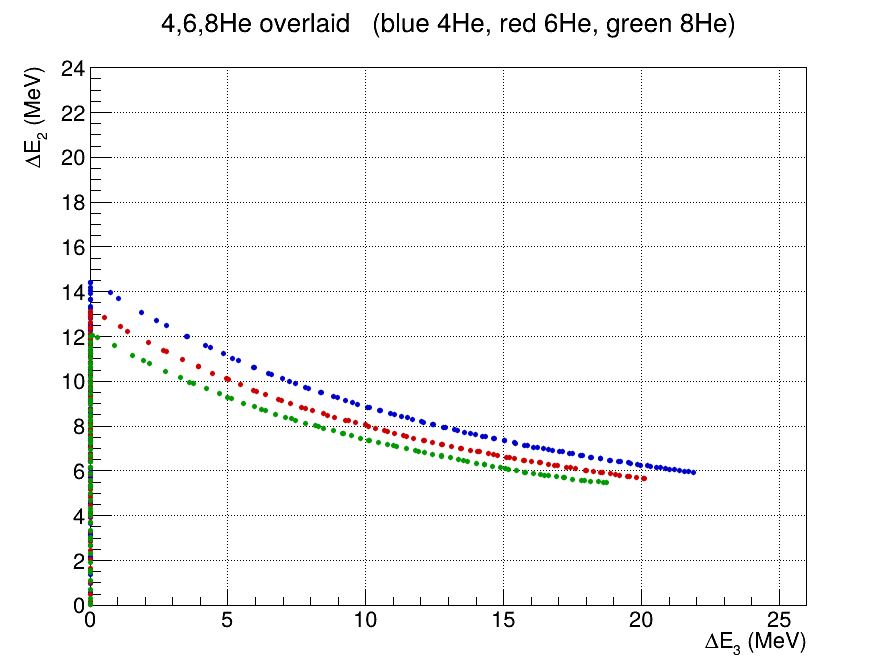

[OK] Fig4_dE2dE3_overlaid -> /home/xugeng/experimental-methods/homework1.2/figs/fig12_Fig4_dE2dE3_overlaid.png
[OK] Fig.4 ΔE2-ΔE3 关联图（4,6,8He）已生成


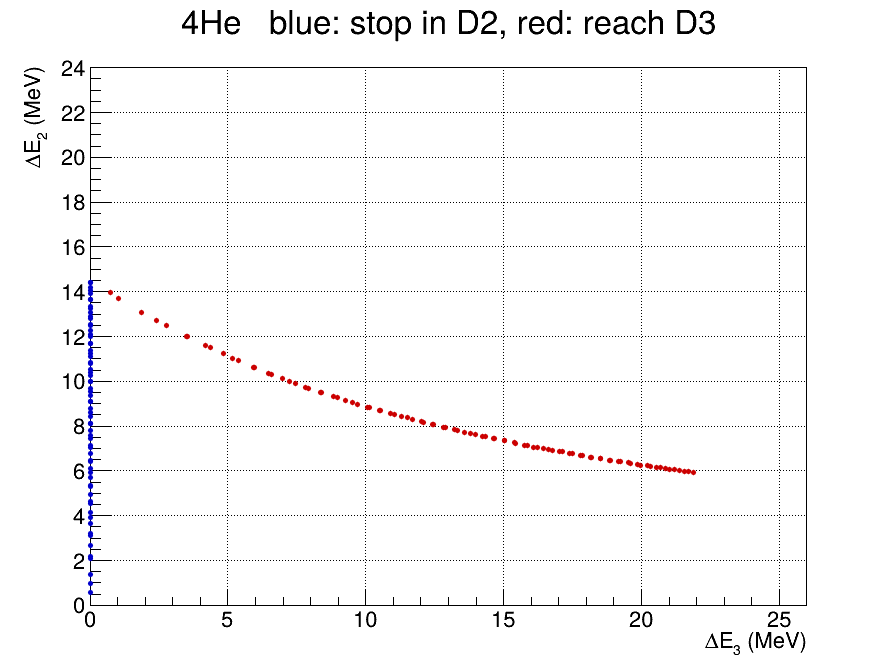

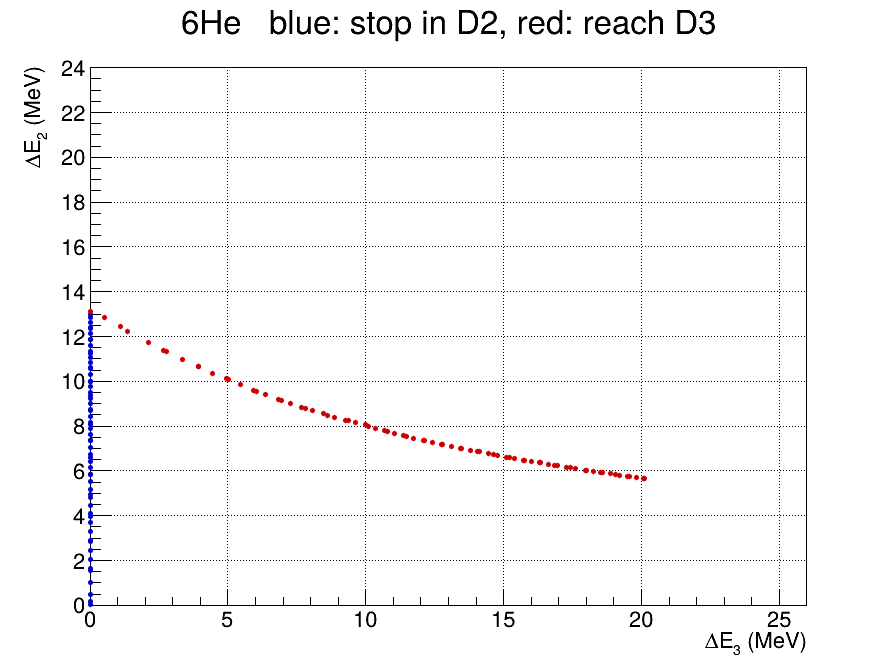

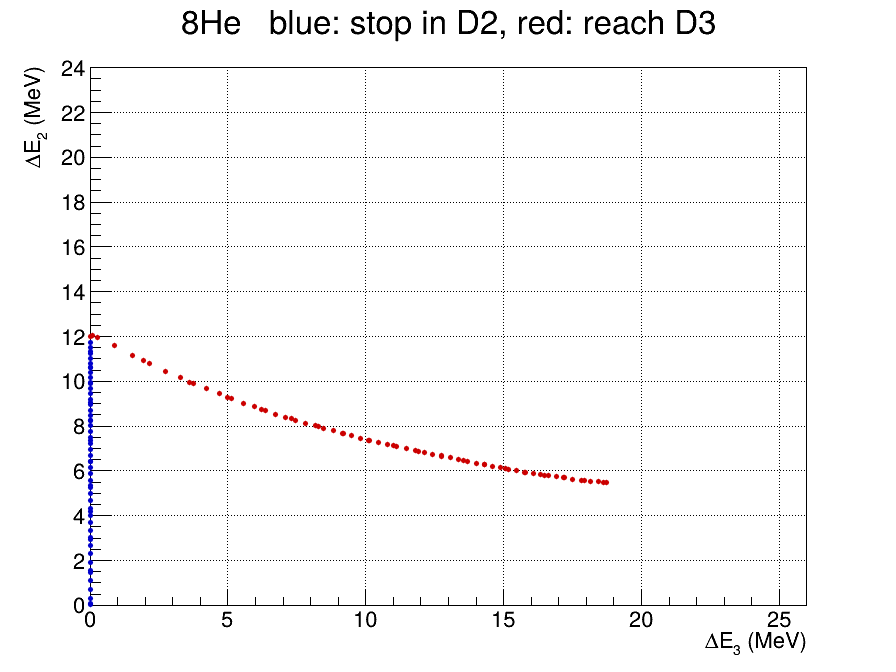

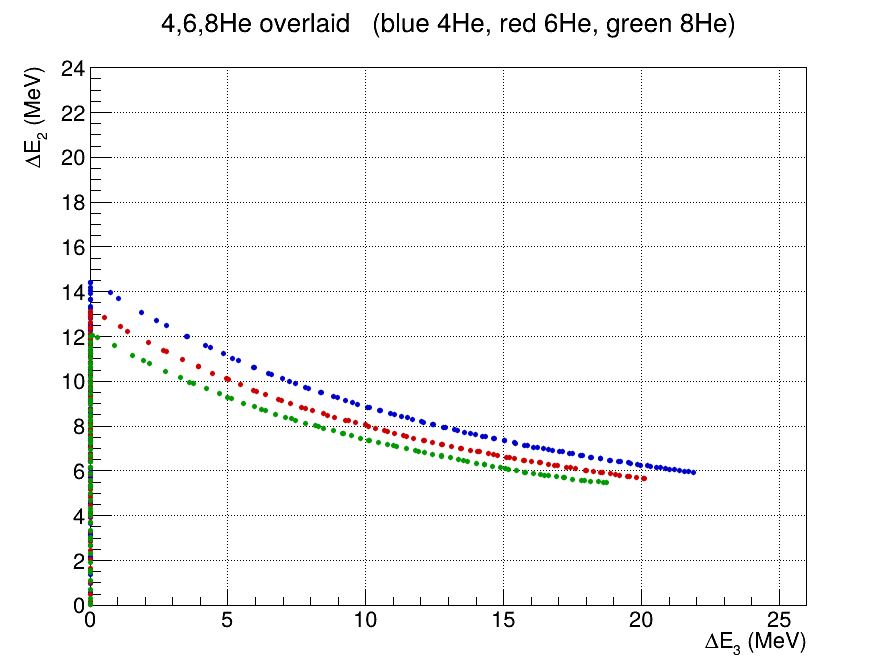

In [13]:
# ========== Cell 12：Fig.4 ΔE2-ΔE3 关联图 ==========
# 横轴 ΔE3、纵轴 ΔE2（与实验数据处理页一致）
draw_pid_panels("4_dE2dE3", "#DeltaE_{3} (MeV)", "#DeltaE_{2} (MeV)", "dE3", "dE2")
print("[OK] Fig.4 ΔE2-ΔE3 关联图（4,6,8He）已生成")

## 6. 穿透点与分支走向的物理解释

沿同一粒子带：

- **停止分支（蓝）**：$\varepsilon$ 增大时 D2 内沉积增加；接近穿透时，$\Delta E_2$ 继续增大，
  而 $\Delta E_1$ 因粒子穿透 D1 后剩余射程变长、D1 内沉积的能量份额下降而**总体减小**。
- **穿透分支（红）**：粒子带着剩余能量离开 D2 后，$\varepsilon$ 继续增大时 500 μm 固定厚度内的沉积
  $\Delta E_2$ 转为下降、而 $\Delta E_1$ 仍在上升，平面轨迹折返，
  表现为 $\Delta E_2$ 增大时 $\Delta E_1$ **总体增加**。
- **穿透点**是两支相接处：$R(E_{\rm in})-t_1-t_2\to 0$，粒子恰好在 D2 后沿耗尽能量，
  此时 $\Delta E_2$ 取极大、$\Delta E_3\to 0$。

下面左图直接给出判据 $R_{\rm rem}(\varepsilon)=R(E_{\rm in})-t_1-t_2$ 的零点，
右图给出穿透点附近三条沉积能量的交叉行为。

Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig13_Fig5a_remaining_range.png has been created


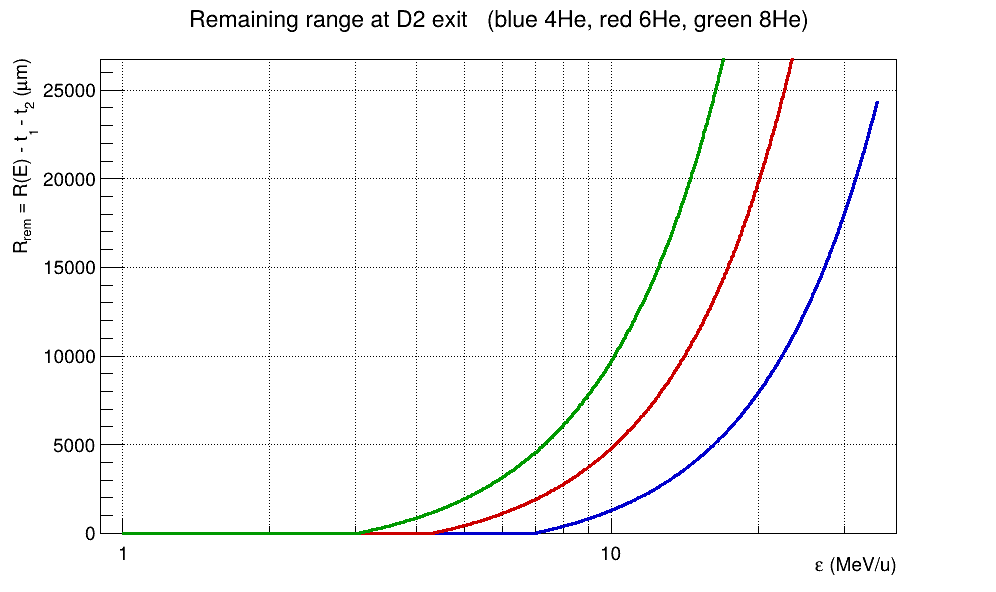

Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig14_Fig5b_deposits_near_punchthrough.png has been created


[OK] Fig5a_remaining_range -> /home/xugeng/experimental-methods/homework1.2/figs/fig13_Fig5a_remaining_range.png


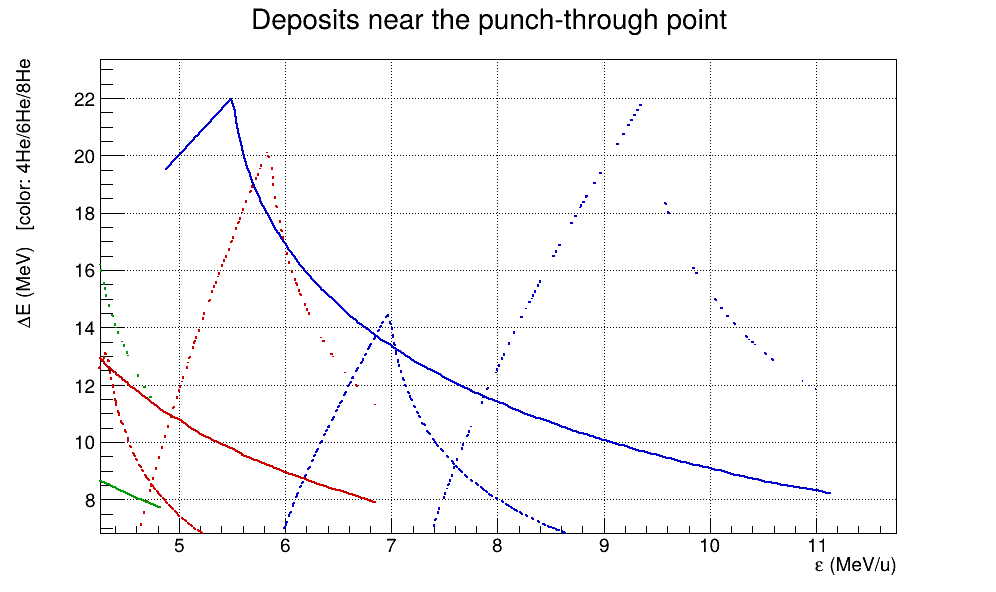

[OK] Fig5b_deposits_near_punchthrough -> /home/xugeng/experimental-methods/homework1.2/figs/fig14_Fig5b_deposits_near_punchthrough.png

========== 穿透点 (D2 -> D3) ==========
    核素     eps_pt (MeV/u)     E_pt (MeV)
   4He             6.9650         27.860
   6He             4.2922         25.753
   8He             3.0162         24.130
[OK] Fig.5 已生成


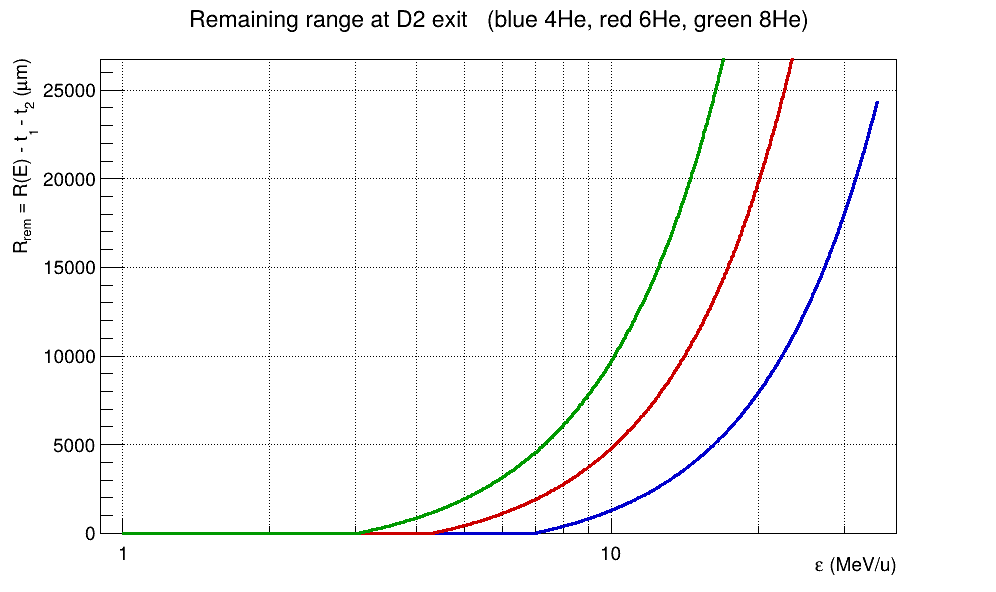

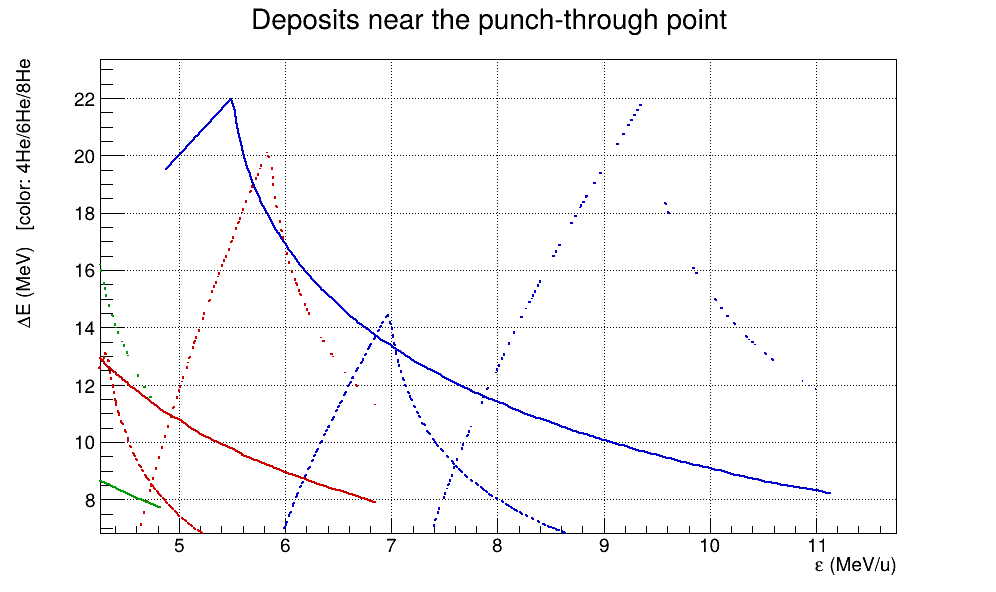

In [14]:
# ========== Cell 13：Fig.5 穿透点定位与穿透点附近的能损 ==========
# ---- 面板 1：D2 出口剩余射程 R_rem(eps)，零点即穿透点 ----
h_pt = None
c = ROOT.TCanvas("c_rem", "Remaining range at D2 exit", 1000, 620)
c.SetLogx()
c.SetGrid()
punch_table = []
for iso in HE_ISOTOPES:
    obj = RE[iso["name"]]
    R_rem = obj.range_after(iso["E_in"], T1 + T2)      # D2 出口剩余射程 (μm)
    iso["R_rem"] = R_rem

    g = tgraph_xy(EPS_GRID, R_rem)
    g.SetLineColor(iso["color"])
    g.SetLineWidth(3)
    if h_pt is None:
        h_pt = g
        g.SetTitle("Remaining range at D2 exit   (blue 4He, red 6He, green 8He);"
                   "#varepsilon (MeV/u);R_{rem} = R(E) - t_{1} - t_{2} (#mum)")
        g.GetYaxis().SetTitleOffset(1.35)
        g.GetYaxis().SetLimits(0.1, 2e5)
    g.Draw("AL" if g is h_pt else "L SAME")

    # 线性插值定位零点（R_rem 在网格上单调上升，取首个符号变化）
    sign = np.sign(R_rem)
    idx = np.where(np.diff(sign) > 0)[0]
    if len(idx):
        i0 = idx[0]
        x0, x1 = EPS_GRID[i0], EPS_GRID[i0 + 1]
        y0, y1 = R_rem[i0], R_rem[i0 + 1]
        eps_pt = x0 + (0.0 - y0) * (x1 - x0) / (y1 - y0)
    else:
        eps_pt = float("nan")
    punch_table.append((iso["name"], eps_pt, eps_pt * iso["A"]))

    if np.isfinite(eps_pt):
        frame = c.GetFrame()
        ln = ROOT.TLine(eps_pt, frame.GetY1(), eps_pt, frame.GetY2())
        ln.SetLineColor(iso["color"])
        ln.SetLineStyle(3)
        ln.SetLineWidth(2)
        ln.Draw()
show(c, "Fig5a_remaining_range")

# ---- 面板 2：穿透点附近三条沉积能量（实线 ΔE1，虚线 ΔE2，点线 ΔE3）----
h_cross = None
c = ROOT.TCanvas("c_cross", "Deposits near punch-through", 1000, 620)
c.SetGrid()
for iso, (nm, eps_pt, E_pt) in zip(HE_ISOTOPES, punch_table):
    if not np.isfinite(eps_pt):
        continue
    sim = iso["sim"]
    m = (EPS_GRID > 0.7 * eps_pt) & (EPS_GRID < 1.6 * eps_pt)
    for key, style in (("dE1", 1), ("dE2", 2), ("dE3", 3)):
        g = tgraph_xy(EPS_GRID[m], sim[key][m])
        g.SetLineColor(iso["color"])
        g.SetLineStyle(style)
        g.SetLineWidth(2)
        if h_cross is None:
            h_cross = g
            g.SetTitle("Deposits near the punch-through point;"
                       "#varepsilon (MeV/u);#DeltaE (MeV)   "
                       "[color: 4He/6He/8He; line: solid #DeltaE_{1}, dashed #DeltaE_{2}, dotted #DeltaE_{3}]")
            g.GetYaxis().SetTitleOffset(1.35)
        g.Draw("AL" if g is h_cross else "L SAME")
show(c, "Fig5b_deposits_near_punchthrough")

print()
print("========== 穿透点 (D2 -> D3) ==========")
print("%6s %18s %14s" % ("核素", "eps_pt (MeV/u)", "E_pt (MeV)"))
for nm, eps_pt, E_pt in punch_table:
    print("%6s %18.4f %14.3f" % (nm, eps_pt, E_pt))
print("[OK] Fig.5 已生成")

Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig15_Fig6a_stop_in_D2.png has been created


[INFO] zoom 范围: x(ΔE2/ΔE3) 0 - 28.5 MeV, y(ΔE1/ΔE2) 0 - 28.6 MeV


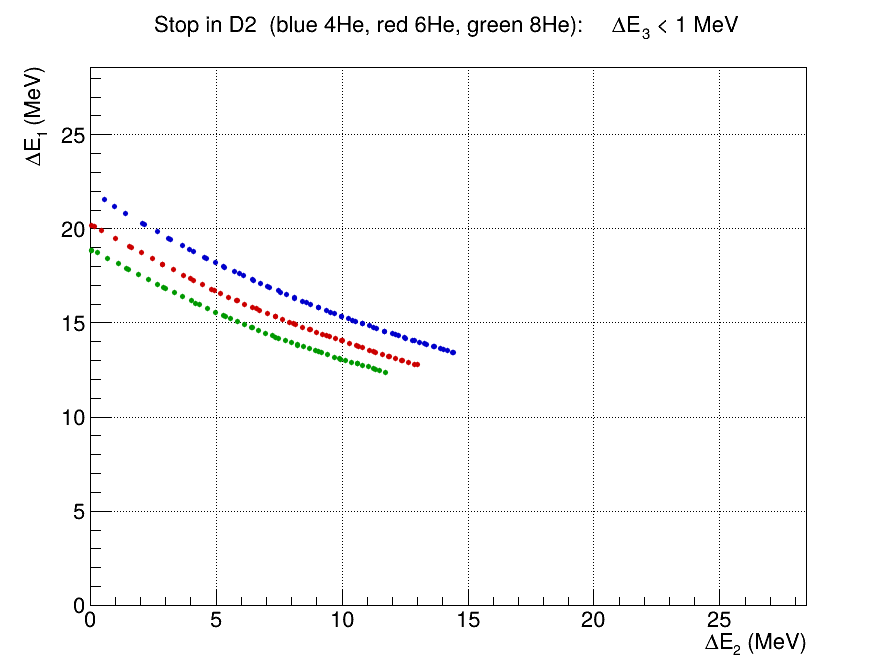

Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/homework1.2/figs/fig16_Fig6b_punch_through_D2.png has been created


[OK] Fig6a_stop_in_D2 -> /home/xugeng/experimental-methods/homework1.2/figs/fig15_Fig6a_stop_in_D2.png


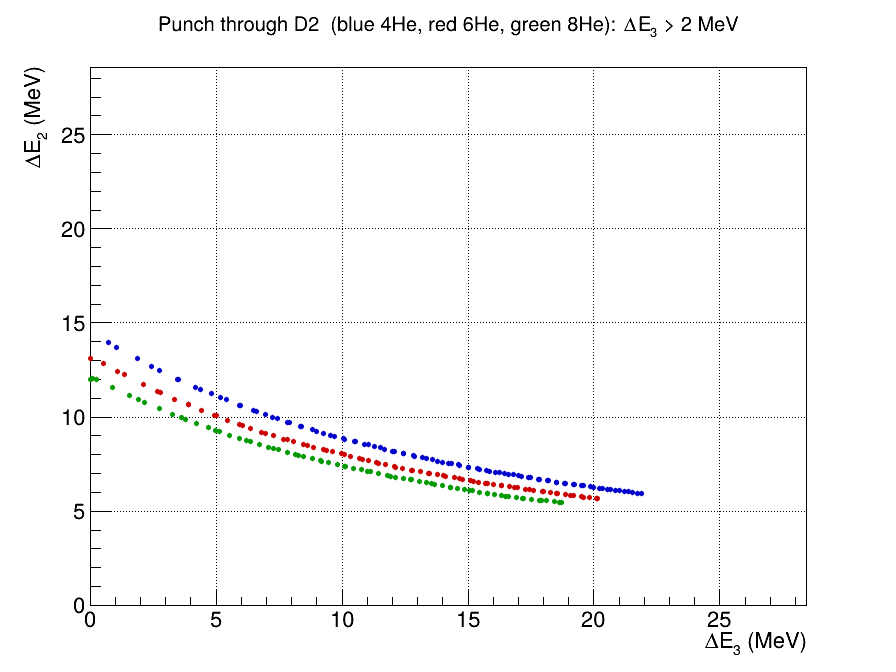

[OK] Fig6b_punch_through_D2 -> /home/xugeng/experimental-methods/homework1.2/figs/fig16_Fig6b_punch_through_D2.png
[OK] Fig.6 已生成


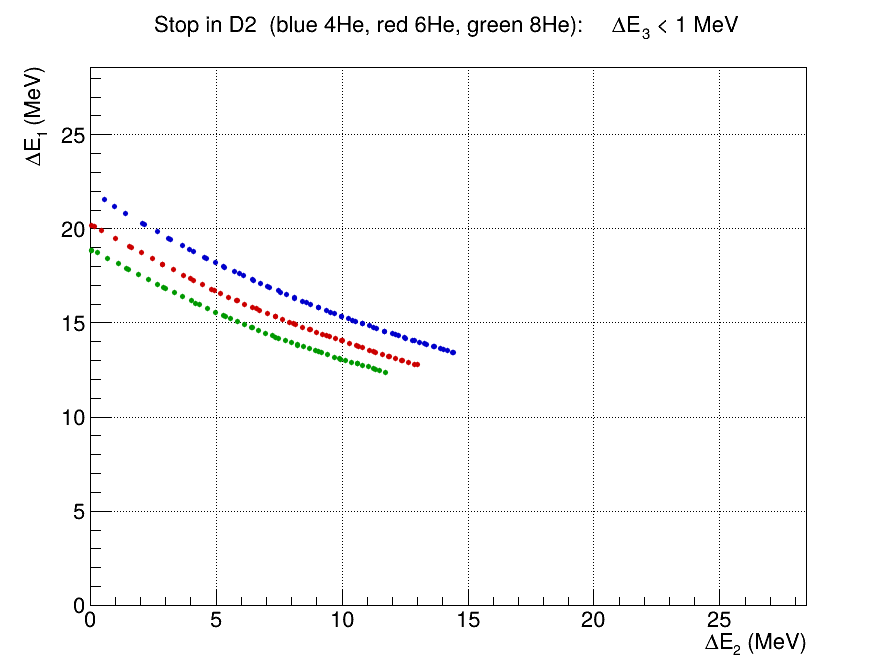

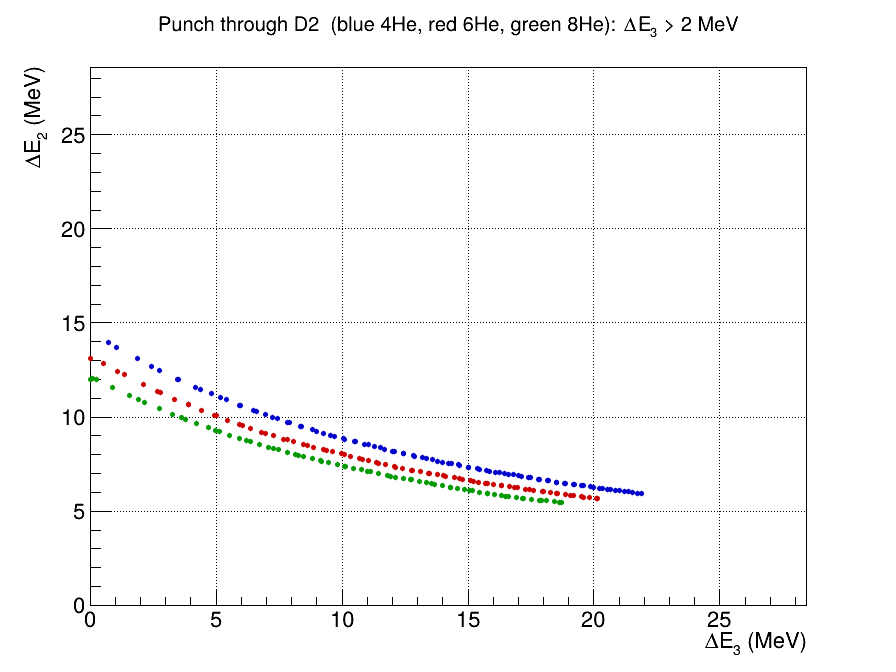

In [15]:
# ========== Cell 14：Fig.6 停止/穿透分栏放大（对应实验页的两分栏图）==========
# 放大范围：把三个同位素的穿透点都包进来
# 左上角（ΔE2 最大、ΔE1 最大）附近就是穿透点，30% 余量已足够包住整个条带
xmax_zoom = 1.30 * max(float(np.max(iso["sim"]["dE2"])) for iso in HE_ISOTOPES)
ymax_zoom = 1.30 * max(float(np.max(iso["sim"]["dE1"])) for iso in HE_ISOTOPES)
xmax_zoom = max(xmax_zoom, 1.30 * max(float(np.max(iso["sim"]["dE3"])) for iso in HE_ISOTOPES))
print("[INFO] zoom 范围: x(ΔE2/ΔE3) 0 - %.1f MeV, y(ΔE1/ΔE2) 0 - %.1f MeV"
      % (xmax_zoom, ymax_zoom))

# ---- 左：停止在 D2 的事件（实验页判据 ΔE3 < 1 MeV）----
c = ROOT.TCanvas("c_stop_zoom", "Stop in D2", 900, 700)
_canvases.append(c)
c.SetGrid()
make_pid_frame("h_stop_zoom",
               "Stop in D2  (blue 4He, red 6He, green 8He):  #DeltaE_{3} < 1 MeV",
               "#DeltaE_{2} (MeV)", "#DeltaE_{1} (MeV)", xmax_zoom, ymax_zoom)
for iso in HE_ISOTOPES:
    m = iso["sim"]["stop"] == 2
    make_pid_graph(iso["sim"]["dE2"][m], iso["sim"]["dE1"][m], iso["color"]).Draw("P SAME")
show(c, "Fig6a_stop_in_D2")

# ---- 右：穿透 D2 的事件（实验页判据 ΔE3 > 2 MeV）----
c = ROOT.TCanvas("c_punch_zoom", "Punch through D2", 900, 700)
_canvases.append(c)
c.SetGrid()
make_pid_frame("h_punch_zoom",
               "Punch through D2  (blue 4He, red 6He, green 8He):  #DeltaE_{3} > 2 MeV",
               "#DeltaE_{3} (MeV)", "#DeltaE_{2} (MeV)", xmax_zoom, ymax_zoom)
for iso in HE_ISOTOPES:
    m = iso["sim"]["stop"] == 3
    if not m.any():
        continue
    make_pid_graph(iso["sim"]["dE3"][m], iso["sim"]["dE2"][m], iso["color"]).Draw("P SAME")
show(c, "Fig6b_punch_through_D2")
print("[OK] Fig.6 已生成")